# Magnificent 7 — Stock Analysis, Portfolio Optimization & Risk Forecasting

**Assets:** AAPL, GOOG, META, AMZN, MSFT, NVDA, TSLA

## Project Overview

An end-to-end quantitative finance project combining **time-series analysis, correlation and risk-return analytics, benchmark evaluation, CAPM, Modern Portfolio Theory (MPT), portfolio optimization, Monte Carlo simulation, Value at Risk (VaR), and portfolio backtesting**.

### Business / Investment Question

> How can historical market data be used to compare seven large-cap technology equities, construct and evaluate a portfolio, quantify downside risk, and test whether optimized weights generalize to unseen market data?

### Core design: a strict 5-year / 5-year split for portfolio fitting and evaluation

| Window | Period | Length | Used for |
|---|---|---|---|
| **Estimation** | 2016-01-01 → 2020-12-31 | 5 years | Portfolio expected returns, covariance matrix, optimization, and correlated portfolio Monte Carlo parameters |
| **Evaluation** | 2021-01-01 → 2025-12-31 | 5 years | Out-of-sample portfolio performance, portfolio Monte Carlo starting prices, and rebalancing backtest |

The portfolio optimizer is fitted only on the estimation window. Its weights are then evaluated on the held-out 2021–2025 window. This prevents the optimizer from using evaluation-period returns when selecting portfolio weights.

### Why the full 2016–2025 history is downloaded

Descriptive analysis — price trends, return distributions, correlations, Beta, Sharpe ratios and CAPM — uses the full available history. The portfolio optimizer and correlated portfolio Monte Carlo use the specified estimation window. The separate NVDA single-stock Monte Carlo uses the full 2016–2025 history and starts from the latest available close; it is not part of the held-out portfolio evaluation.

**Universe caveat:** The Magnificent 7 is a retrospectively defined group. Studying these companies over 2016–2025 therefore involves selection/survivorship bias; the historical results should not be interpreted as an ex-ante stock-selection strategy.

### Analytical Workflow

1. **Data Acquisition** — daily adjusted closing prices for 2016–2025 via `yfinance`
2. **Estimation / Evaluation Split** — 2016–2020 estimation window and 2021–2025 evaluation window
3. **EDA** — price trends, normalized performance and moving averages
4. **Risk & Return** — daily returns, normality testing, annualized return/volatility, Beta, Sharpe Ratio and correlation
5. **Benchmarking** — equal-weight Magnificent 7 vs S&P 500 and QQQ
6. **CAPM** — systematic risk and Jensen-style alpha
7. **Portfolio Optimization** — efficient frontier, maximum-Sharpe and minimum-variance portfolios fitted on the estimation window
8. **Out-of-Sample Validation** — fixed optimized weights evaluated on 2021–2025 against Equal-Weight, S&P 500 and QQQ
9. **Risk Forecasting** — NVDA single-stock GBM simulation and correlated seven-stock portfolio Monte Carlo using Cholesky decomposition
10. **Strategy Backtest** — monthly rebalancing vs Buy & Hold

> **Assumptions:** Risk-free rate fixed at **5.0% annually** for Sharpe and CAPM calculations. Returns are annualized using 252 trading days. Transaction costs, taxes and market impact are not modeled.


## 1. Importing Libraries

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

from scipy import stats
from scipy.optimize import minimize

sns.set_style('whitegrid')
warnings.simplefilter(action='ignore', category=FutureWarning)
%matplotlib inline

## 2. Configuration

Every parameter that drives the analysis is defined once here, so the notebook can be re-run on a different universe, window, or risk-free assumption by editing a single cell.

In [2]:
# -----------------------------------
# Global configuration
# -----------------------------------

TICKERS = ['AAPL', 'GOOG', 'META', 'AMZN', 'MSFT', 'NVDA', 'TSLA']

START_DATE = '2016-01-01'
END_DATE   = '2026-01-01'          # exclusive upper bound -> includes all of 2025

EST_START, EST_END = '2016-01-01', '2020-12-31'   # estimation window (model fitting)
EVA_START, EVA_END = '2021-01-01', '2025-12-31'   # evaluation window (out-of-sample)

RISK_FREE_RATE = 0.05              # 5.0% annual, fixed assumption
TRADING_DAYS   = 252
SEED           = 42

N_RANDOM_PORTFOLIOS = 20_000
N_SIMULATIONS       = 10_000
HORIZON_DAYS        = 252

COLORS = sns.color_palette('tab10', len(TICKERS))

print(f'Universe          : {", ".join(TICKERS)}')
print(f'Estimation window : {EST_START} to {EST_END}')
print(f'Evaluation window : {EVA_START} to {EVA_END}')
print(f'Risk-free rate    : {RISK_FREE_RATE:.2%} (fixed)')

Universe          : AAPL, GOOG, META, AMZN, MSFT, NVDA, TSLA
Estimation window : 2016-01-01 to 2020-12-31
Evaluation window : 2021-01-01 to 2025-12-31
Risk-free rate    : 5.00% (fixed)


## 3. Data Acquisition

Daily **adjusted closing prices** are downloaded for the full 2016–2025 history.

**Why adjusted prices?** Adjusted prices account for corporate actions such as stock splits and dividends, making them appropriate for return and portfolio analysis. NVIDIA and Tesla both executed splits inside this window, so unadjusted prices would produce false crashes in the return series.

A single `download_close()` helper is used for every download in the notebook — the Magnificent 7, the S&P 500, and QQQ — so the alignment and column-handling logic exists in exactly one place and cannot drift between sections.

In [3]:
# -----------------------------------
# Data Acquisition
# -----------------------------------

def download_close(symbols, start=START_DATE, end=END_DATE):
    # Download adjusted close prices.
    # Returns a Series for a single symbol, a DataFrame for a list of symbols.
    raw = yf.download(symbols, start=start, end=end, auto_adjust=True, progress=False)

    if raw.empty:
        raise ValueError(f'No data returned for {symbols}. Check connectivity or Yahoo Finance availability.')

    close = raw['Close'] if isinstance(raw.columns, pd.MultiIndex) else raw[['Close']]

    if isinstance(symbols, str):
        return pd.Series(close.squeeze()).dropna().rename(symbols)

    return close.reindex(columns=symbols).dropna(how='all').ffill().dropna()


data = download_close(TICKERS)

print(f'Shape       : {data.shape}')
print(f'Date range  : {data.index[0].date()} to {data.index[-1].date()}')
print(f'Trading days: {len(data):,}')
print(f'Missing     : {int(data.isna().sum().sum())}')

data.tail()

Shape       : (2514, 7)
Date range  : 2016-01-04 to 2025-12-31
Trading days: 2,514
Missing     : 0


Ticker,AAPL,GOOG,META,AMZN,MSFT,NVDA,TSLA
Date,,,,,,,
2025-12-24,273.066742,315.053497,665.835938,232.380005,484.943420,188.169678,485.399994
2025-12-26,272.657806,314.344879,661.586792,232.520004,484.635406,190.085205,475.190002
2025-12-29,273.016876,313.776031,656.998657,232.070007,484.029236,187.780594,459.640015
2025-12-30,272.338684,313.935669,664.239990,232.529999,484.406860,187.102173,454.429993
2025-12-31,271.122009,313.187134,658.395081,230.820007,480.571167,186.064606,449.720001


## 4. Estimation / Evaluation Split

The price history is divided into two non-overlapping five-year blocks for portfolio fitting and evaluation.

- **Estimation window (2016–2020)** — used to estimate portfolio expected returns and covariance, fit the MPT portfolios, and estimate parameters for the correlated seven-stock Monte Carlo simulation.
- **Evaluation window (2021–2025)** — held out from portfolio optimization and used to evaluate the fixed portfolio weights out of sample.

The optimizer does not use evaluation-window returns when selecting weights. This reduces look-ahead bias in the portfolio performance test. The separate descriptive analysis and NVDA single-stock Monte Carlo have their own scopes, which are stated in their respective sections.


In [4]:
data_estimation = data.loc[EST_START:EST_END].copy()
data_evaluation = data.loc[EVA_START:EVA_END].copy()

print('Estimation window')
print(f'  {data_estimation.index[0].date()} to {data_estimation.index[-1].date()}  ({len(data_estimation):,} trading days)')
print('Evaluation window')
print(f'  {data_evaluation.index[0].date()} to {data_evaluation.index[-1].date()}  ({len(data_evaluation):,} trading days)')

assert data_estimation.index.max() < data_evaluation.index.min(), 'Windows overlap — look-ahead bias!'
print('\nNo overlap between windows confirmed.')

Estimation window
  2016-01-04 to 2020-12-31  (1,259 trading days)
Evaluation window
  2021-01-04 to 2025-12-31  (1,255 trading days)

No overlap between windows confirmed.


## 5. Exploratory Data Analysis

### 5.1 Individual Closing Price Charts

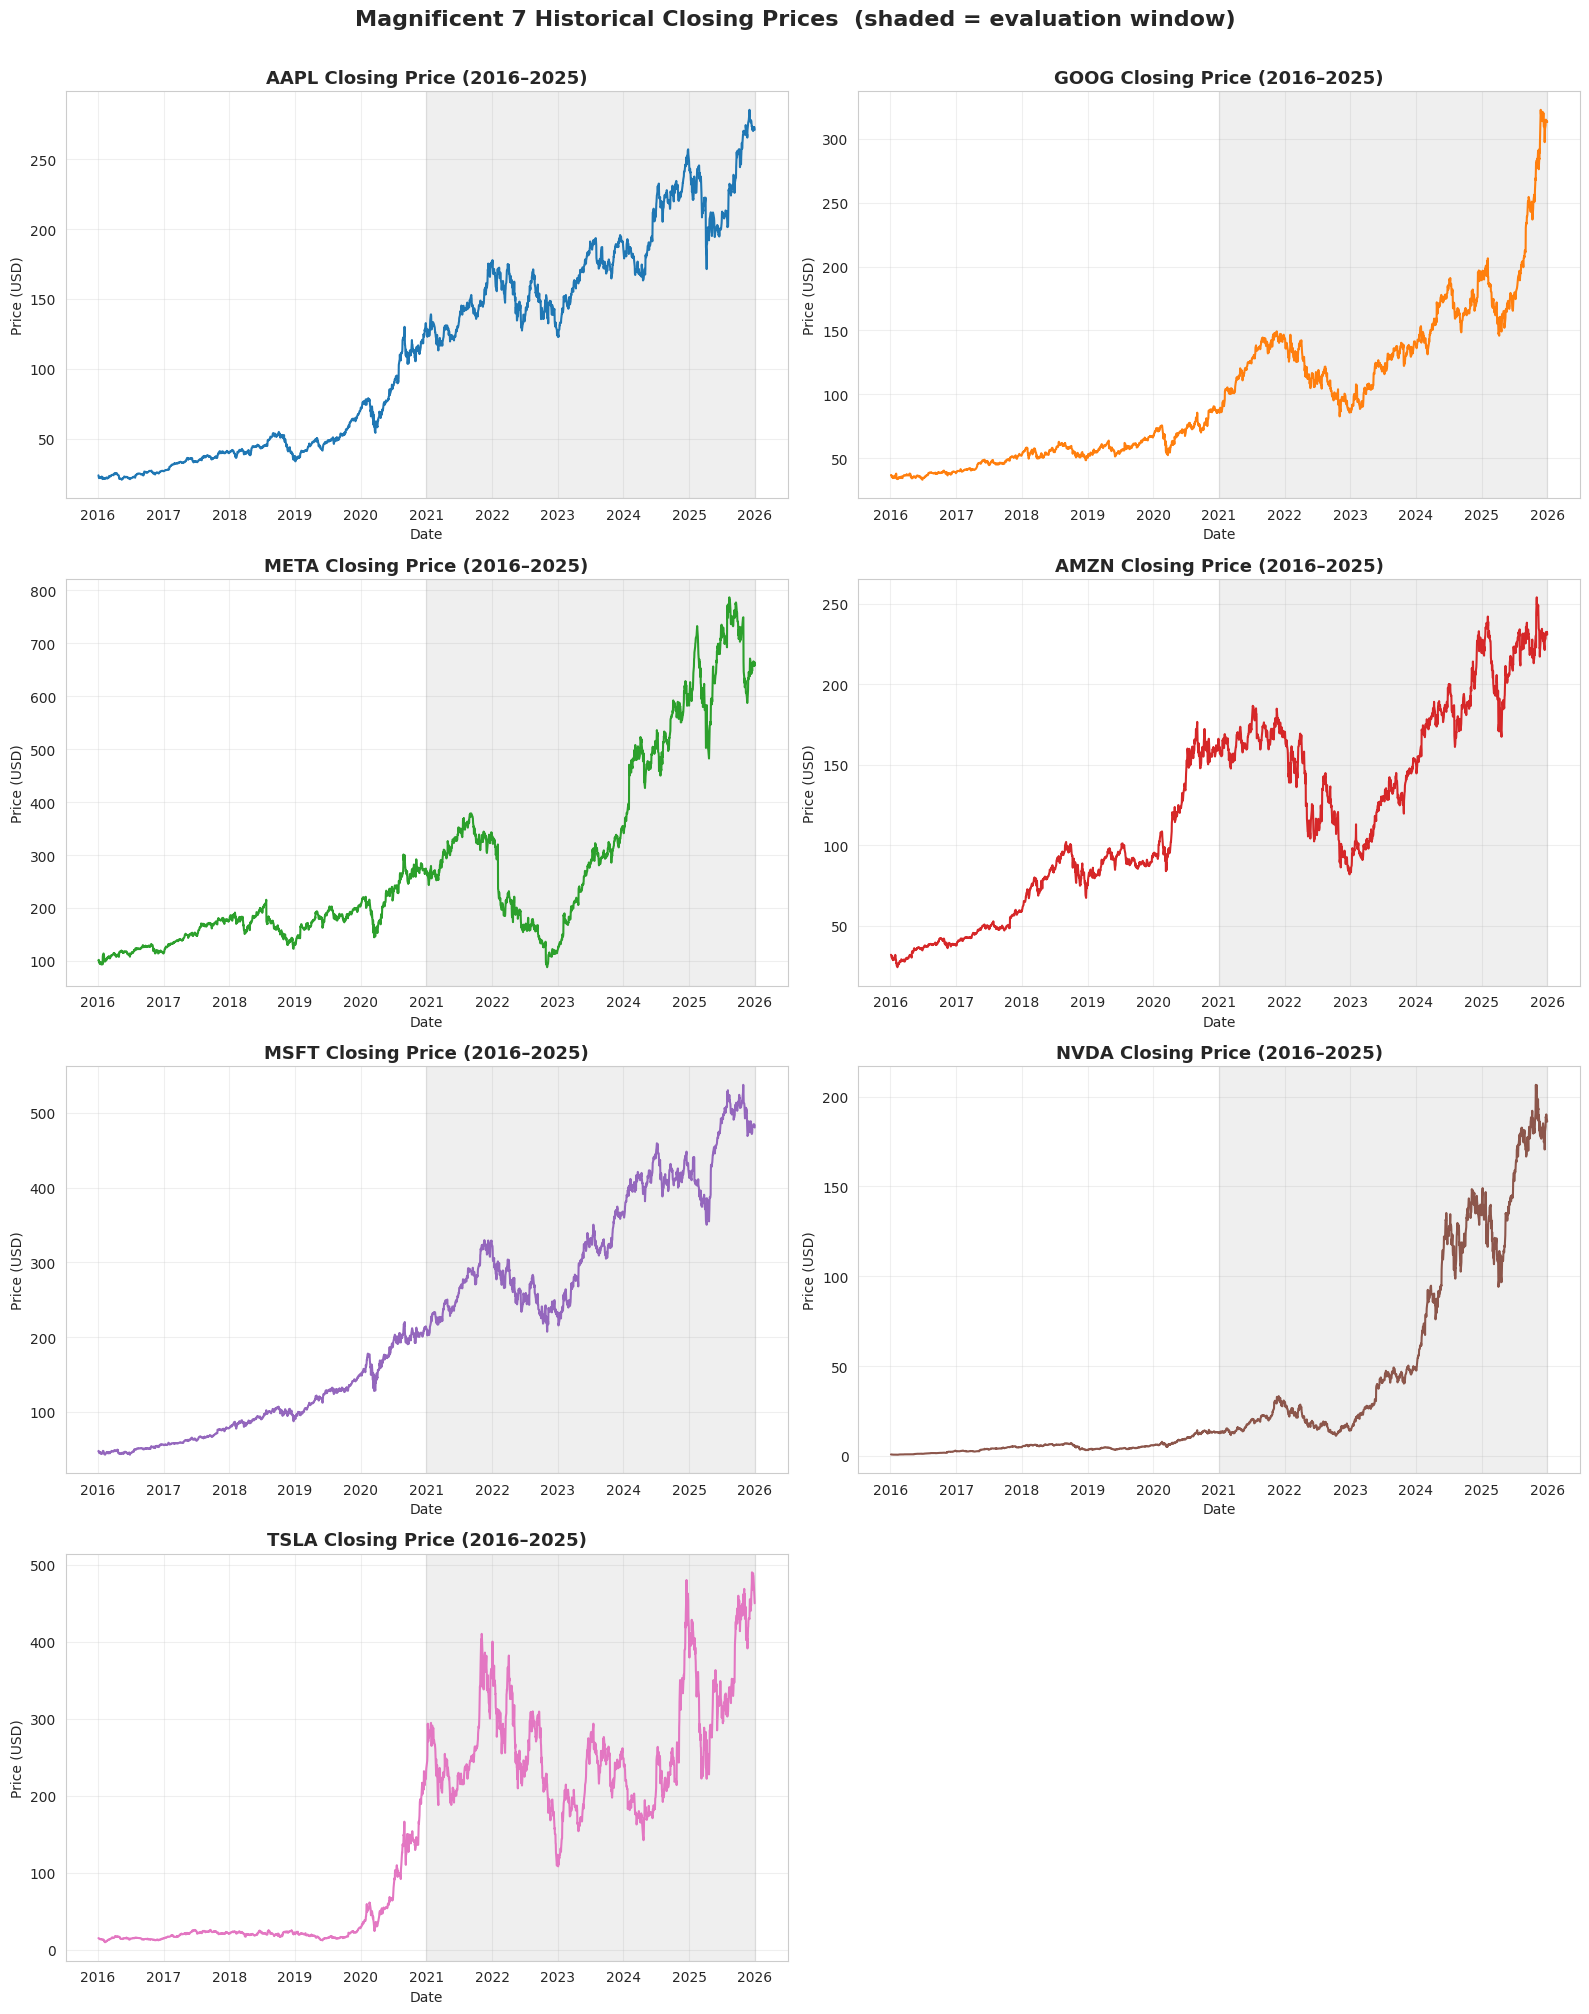

In [5]:
fig, axes = plt.subplots(4, 2, figsize=(16, 20))
axes = axes.flatten()

for i, ticker in enumerate(TICKERS):
    axes[i].plot(data.index, data[ticker], color=COLORS[i], linewidth=1.5)
    axes[i].axvspan(pd.Timestamp(EVA_START), data.index[-1], color='grey', alpha=0.12)
    axes[i].set_title(f'{ticker} Closing Price (2016–2025)', fontsize=13, fontweight='bold')
    axes[i].set_xlabel('Date')
    axes[i].set_ylabel('Price (USD)')
    axes[i].grid(True, alpha=0.3)

fig.delaxes(axes[7])
plt.suptitle('Magnificent 7 Historical Closing Prices  (shaded = evaluation window)',
             fontsize=16, fontweight='bold', y=1.005)
plt.tight_layout()
plt.show()

### 5.2 Normalized Price Comparison (Base = 100)

Raw price levels are not comparable across stocks because each starts at a different price. Rebasing every series to 100 on the first trading day makes cumulative percentage growth directly comparable.

Formula: `Normalized = (Price / First Price) × 100`

A **log scale** is used because the dispersion across these seven names spans three orders of magnitude — on a linear axis NVIDIA's path compresses every other line onto the floor of the chart.

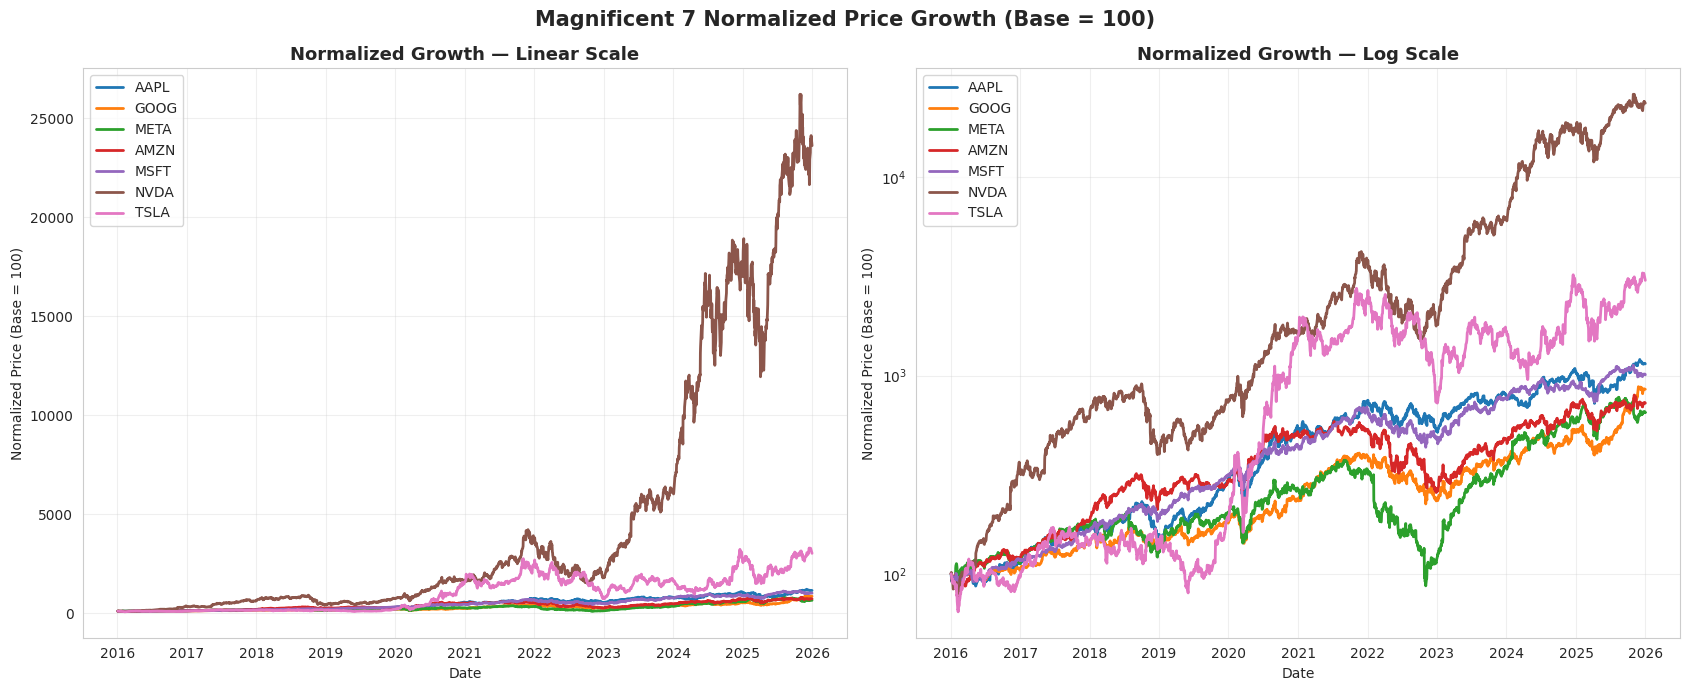

Cumulative Return Summary (2016–2025):
------------------------------------------
  AAPL :    +1044.5%
  GOOG :     +752.3%
  META :     +550.3%
  AMZN :     +624.7%
  MSFT :     +907.9%
  NVDA :   +23519.9%
  TSLA :    +2919.5%


In [6]:
normalized = (data / data.iloc[0]) * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 7))

for i, ticker in enumerate(TICKERS):
    ax1.plot(normalized.index, normalized[ticker], label=ticker, color=COLORS[i], linewidth=2)
    ax2.plot(normalized.index, normalized[ticker], label=ticker, color=COLORS[i], linewidth=2)

ax1.set_title('Normalized Growth — Linear Scale', fontsize=13, fontweight='bold')
ax2.set_yscale('log')
ax2.set_title('Normalized Growth — Log Scale', fontsize=13, fontweight='bold')

for ax in (ax1, ax2):
    ax.set_xlabel('Date')
    ax.set_ylabel('Normalized Price (Base = 100)')
    ax.legend(loc='upper left', fontsize=10)
    ax.grid(True, alpha=0.3)

plt.suptitle('Magnificent 7 Normalized Price Growth (Base = 100)', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

print('Cumulative Return Summary (2016–2025):')
print('-' * 42)
for ticker in TICKERS:
    r = (data[ticker].iloc[-1] / data[ticker].iloc[0] - 1) * 100
    print(f'  {ticker:5s}: {r:+10.1f}%')

### Key Insights

- Over the **2016–2025** downloaded period, cumulative returns were highly dispersed: **NVDA +23,519.9%**, **TSLA +2,919.5%**, **AAPL +1,044.5%**, **MSFT +907.9%**, **GOOG +752.3%**, **AMZN +624.7%**, and **META +550.3%**.
- NVIDIA is a pronounced outlier in cumulative performance; the other six stocks also show substantial differences in growth.
- The log-scale panel makes the divergence easier to compare across assets with very different cumulative returns.
- Strong cumulative performance should be read alongside volatility, drawdown and correlation rather than in isolation.
- These are retrospective results for a group selected with hindsight, not evidence that the same seven-stock universe could have been selected in advance.


### 5.3 Moving Averages — Google Deep Dive

Moving averages smooth short-term noise to expose the underlying trend.

- **10-day MA** — short-term trend
- **25-day MA** — medium-term trend
- **50-day MA** — long-term sentiment indicator

Two comparisons are shown:

1. **SMA 10 / 25 / 50** — the crossover structure. A **Golden Cross** (MA-10 crossing above MA-50) is conventionally read as bullish; a **Death Cross** (MA-10 crossing below MA-50) as bearish.
2. **SMA 50 vs EMA 50** — the same lookback, weighted differently. The EMA front-loads recent observations and therefore turns earlier.

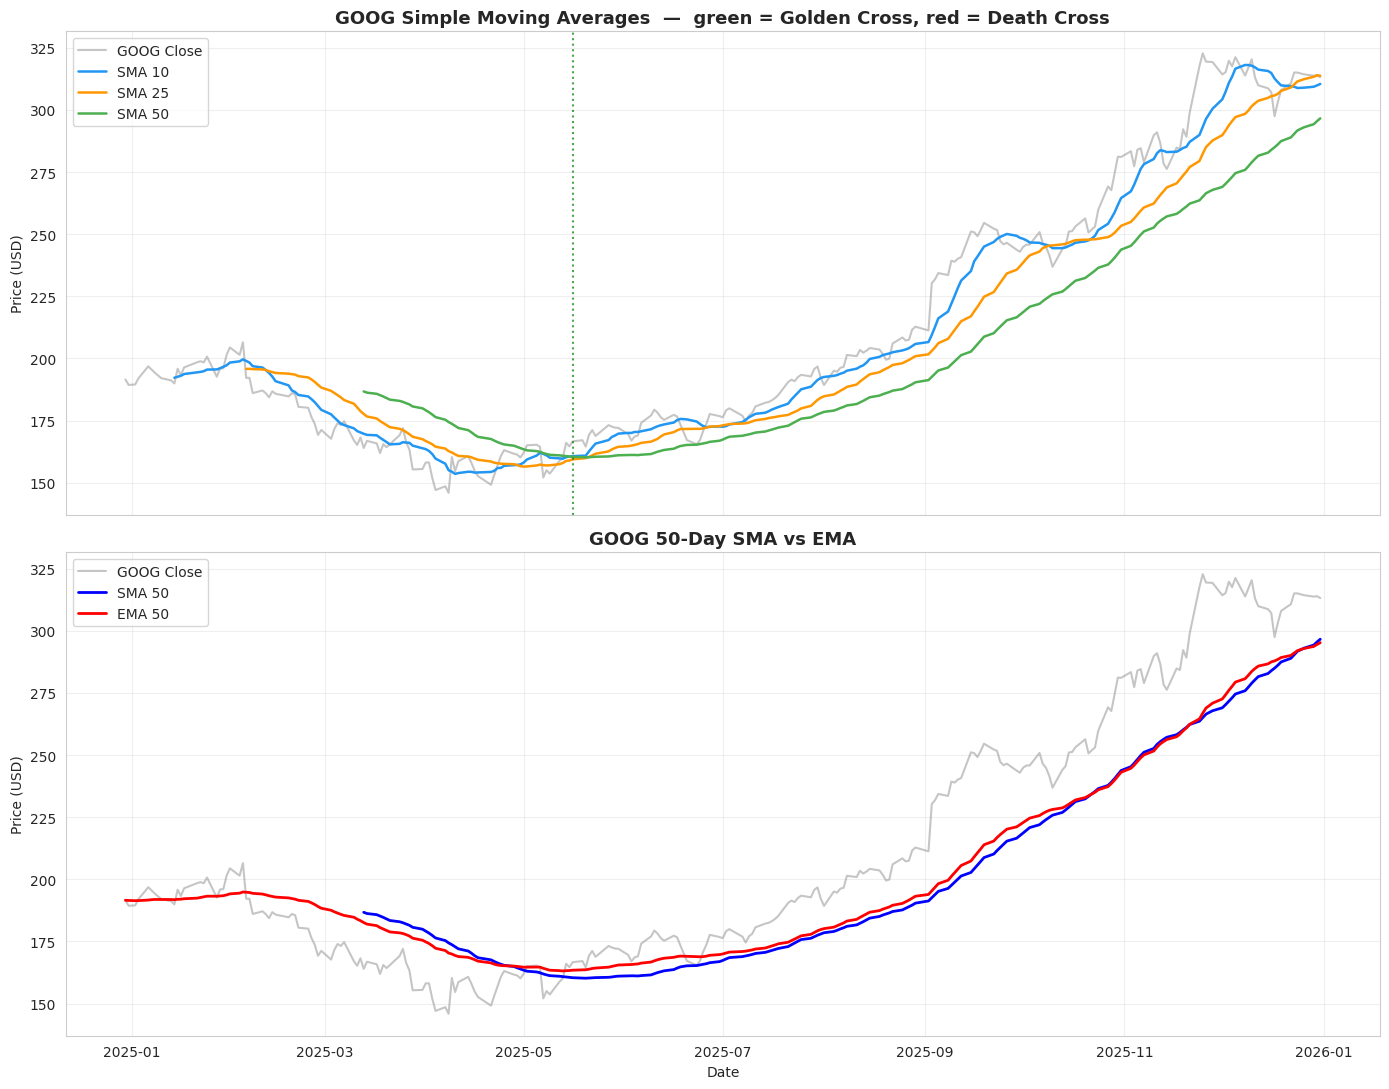

Golden Crosses in last 252 trading days: 1
Death  Crosses in last 252 trading days: 0


In [7]:
goog = data[['GOOG']].tail(TRADING_DAYS).copy()

for window in (10, 25, 50):
    goog[f'SMA_{window}'] = goog['GOOG'].rolling(window=window).mean()
    goog[f'EMA_{window}'] = goog['GOOG'].ewm(span=window, adjust=False).mean()

# Detect golden / death crosses (SMA-10 vs SMA-50)
signal = np.sign(goog['SMA_10'] - goog['SMA_50'])
crosses = signal.diff().fillna(0)
golden = goog.index[crosses > 0]
death  = goog.index[crosses < 0]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 11), sharex=True)

ax1.plot(goog['GOOG'], color='gray', alpha=0.45, label='GOOG Close')
ax1.plot(goog['SMA_10'], color='#2196F3', linewidth=1.8, label='SMA 10')
ax1.plot(goog['SMA_25'], color='#FF9800', linewidth=1.8, label='SMA 25')
ax1.plot(goog['SMA_50'], color='#4CAF50', linewidth=1.8, label='SMA 50')

for d in golden:
    ax1.axvline(d, color='green', linestyle=':', alpha=0.7)
for d in death:
    ax1.axvline(d, color='red', linestyle=':', alpha=0.7)

ax1.set_title('GOOG Simple Moving Averages  —  green = Golden Cross, red = Death Cross',
              fontsize=13, fontweight='bold')
ax1.set_ylabel('Price (USD)')
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3)

ax2.plot(goog['GOOG'], color='gray', alpha=0.45, label='GOOG Close')
ax2.plot(goog['SMA_50'], color='blue', linewidth=2, label='SMA 50')
ax2.plot(goog['EMA_50'], color='red', linewidth=2, label='EMA 50')
ax2.set_title('GOOG 50-Day SMA vs EMA', fontsize=13, fontweight='bold')
ax2.set_xlabel('Date')
ax2.set_ylabel('Price (USD)')
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f'Golden Crosses in last {TRADING_DAYS} trading days: {len(golden)}')
print(f'Death  Crosses in last {TRADING_DAYS} trading days: {len(death)}')

### Insights

- The EMA reacts faster than the SMA at the same 50-day lookback because it assigns geometrically declining weights to older observations; the SMA weights every day in the window equally.
- The SMA therefore gives a smoother read of the underlying trend, while the EMA gives an earlier — and noisier — signal.
- Crossovers cluster around trend reversals but also fire repeatedly inside sideways ranges. That whipsaw behaviour is why crossovers are treated here as **descriptive trend indicators, not standalone trading signals**, and why no crossover rule is carried into the backtest in Section 12.

## 6. Risk & Return Analysis

### 6.1 Daily Return Distributions

`Daily Return = (Today − Yesterday) / Yesterday`

A wider distribution means more volatility, which means more risk.

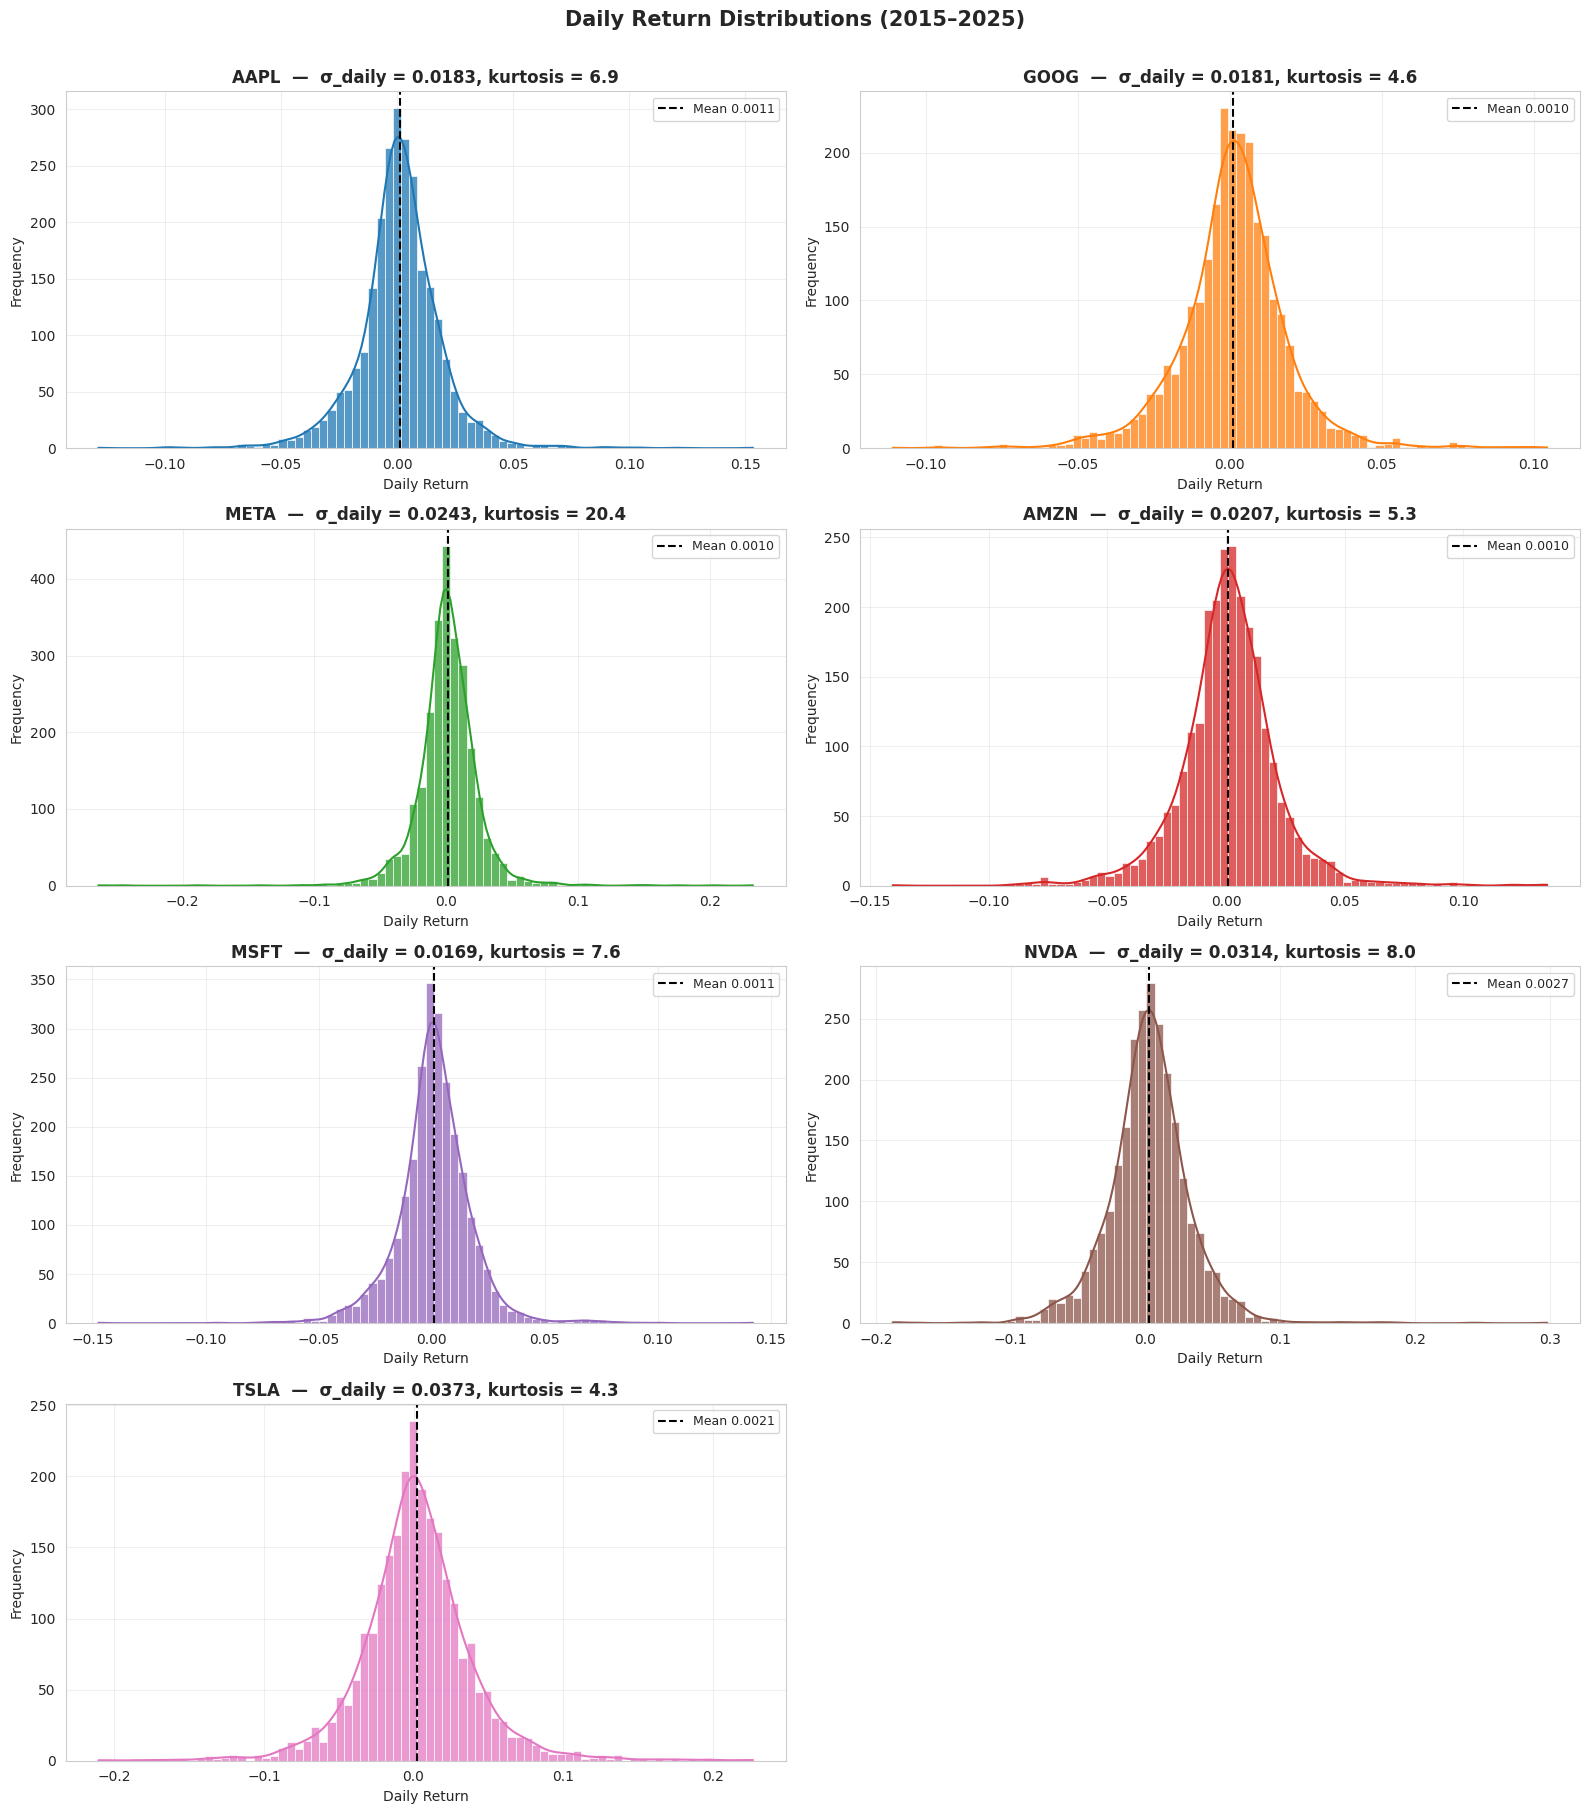

In [8]:
daily_returns = data.pct_change().dropna()

fig, axes = plt.subplots(4, 2, figsize=(16, 18))
axes = axes.flatten()

for i, ticker in enumerate(TICKERS):
    sns.histplot(daily_returns[ticker], bins=80, kde=True, color=COLORS[i],
                 alpha=0.75, edgecolor='white', ax=axes[i])

    axes[i].axvline(daily_returns[ticker].mean(), color='black', linestyle='--',
                    linewidth=1.5, label=f"Mean {daily_returns[ticker].mean():.4f}")

    axes[i].set_title(
        f'{ticker}  —  σ_daily = {daily_returns[ticker].std():.4f}, '
        f'kurtosis = {daily_returns[ticker].kurtosis():.1f}',
        fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Daily Return')
    axes[i].set_ylabel('Frequency')
    axes[i].legend(fontsize=9)
    axes[i].grid(True, alpha=0.3)

fig.delaxes(axes[7])
plt.suptitle('Daily Return Distributions (2015–2025)', fontsize=15, fontweight='bold', y=1.005)
plt.tight_layout()
plt.show()

### Insights

- Daily return distributions are centred close to zero, while their standard deviations describe the much larger day-to-day variation.
- All seven series show **positive excess kurtosis**, indicating heavier tails than a normal distribution.
- The higher-volatility names show wider distributions and more pronounced extreme observations.
- The fat tails motivate explicit downside-risk analysis; volatility alone does not describe the full range of potential losses.


### 6.2 Normality Testing of Daily Returns

Many standard finance models — including the Geometric Brownian Motion used later for Monte Carlo — assume returns are normally distributed. That assumption is worth testing rather than inheriting.

The **D'Agostino–Pearson K² test** combines skewness and kurtosis into a single statistic. A p-value below 0.05 rejects normality. **Q-Q plots** visualize the same question: under normality the points lie on the diagonal; tails bending away from the line indicate fat tails.

Normality Test (D'Agostino–Pearson K²)
--------------------------------------------------------------
Stock        p-value      Skew    Kurtosis       Normal?
--------------------------------------------------------------
AAPL        2.08e-80      0.15        6.94      Rejected
GOOG        2.92e-58     -0.01        4.61      Rejected
META       2.53e-143     -0.24       20.42      Rejected
AMZN        4.52e-68      0.20        5.26      Rejected
MSFT        4.86e-84      0.08        7.64      Rejected
NVDA       3.21e-107      0.51        7.96      Rejected
TSLA        5.69e-62      0.28        4.28      Rejected


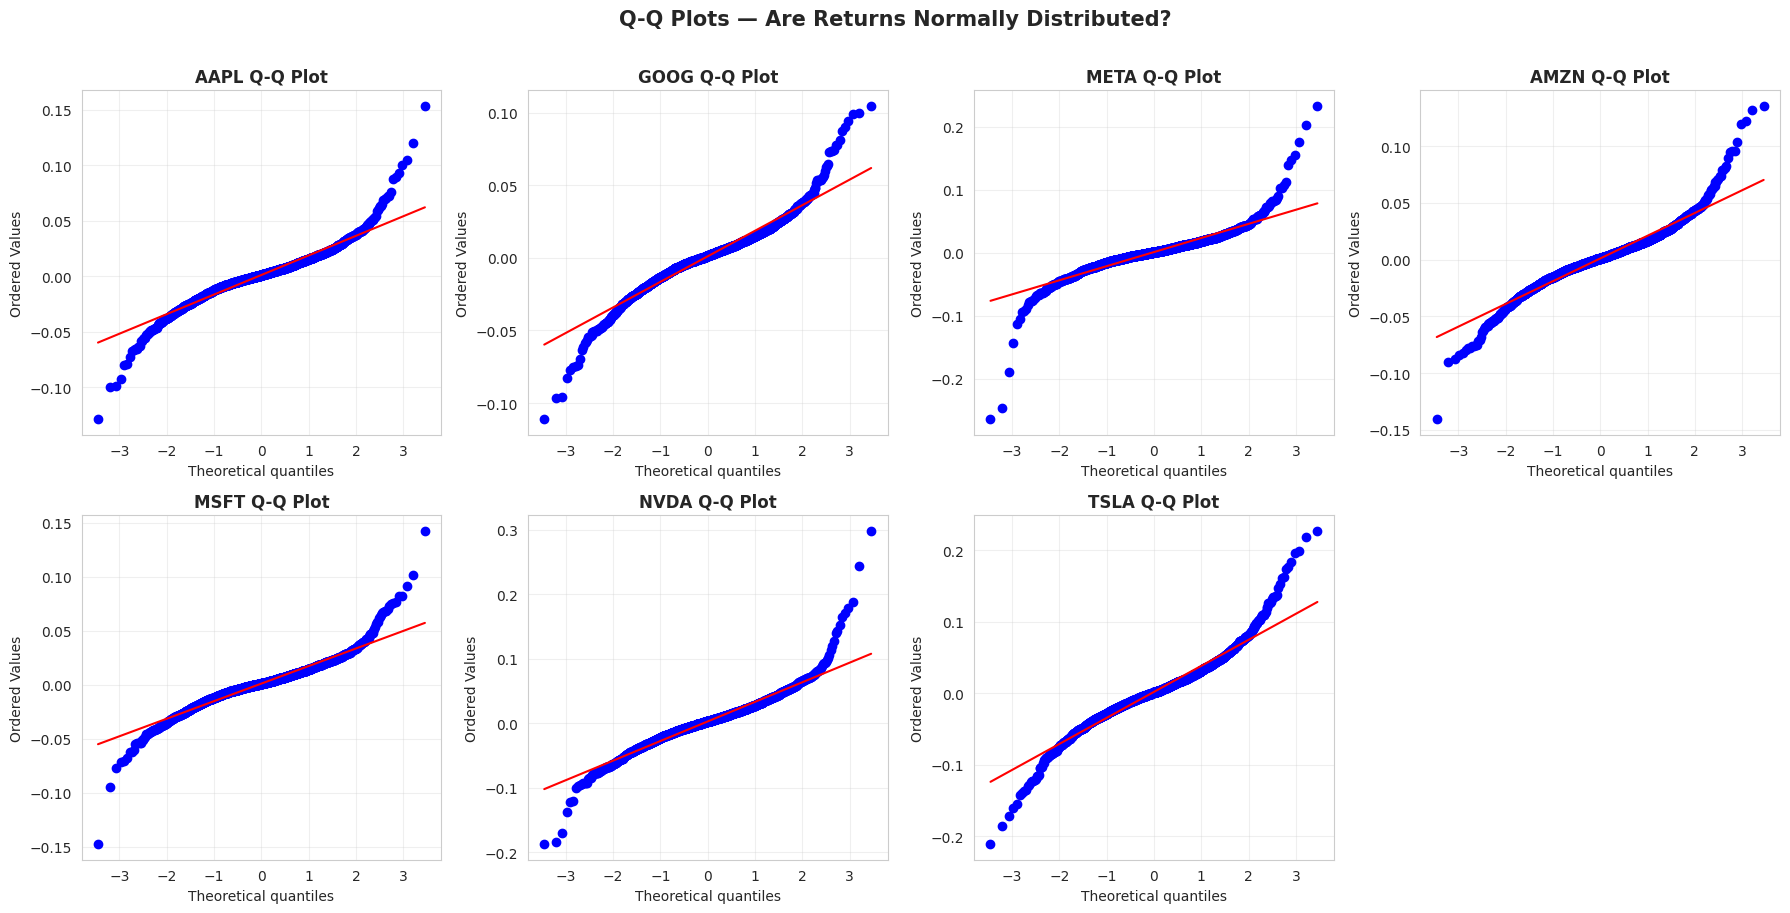

In [9]:
print("Normality Test (D'Agostino–Pearson K²)")
print('-' * 62)
print(f"{'Stock':<8}{'p-value':>12}{'Skew':>10}{'Kurtosis':>12}{'Normal?':>14}")
print('-' * 62)

for ticker in TICKERS:
    series = daily_returns[ticker].dropna()
    stat, p = stats.normaltest(series)
    verdict = 'Rejected' if p < 0.05 else 'Not rejected'
    print(f'{ticker:<8}{p:>12.2e}{series.skew():>10.2f}{series.kurtosis():>12.2f}{verdict:>14}')

fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.flatten()

for i, ticker in enumerate(TICKERS):
    stats.probplot(daily_returns[ticker].dropna(), plot=axes[i])
    axes[i].set_title(f'{ticker} Q-Q Plot', fontsize=12, fontweight='bold')
    axes[i].grid(True, alpha=0.3)

fig.delaxes(axes[7])
plt.suptitle('Q-Q Plots — Are Returns Normally Distributed?', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

### Key Findings — Distribution & Normality

- Normality is **rejected for all seven stocks** at the 5% level, with p-values effectively zero (< 0.0001 for every name). This is not a borderline result.
- The Q-Q plots show the classic signature: points track the diagonal through the middle of the distribution and bend sharply away at both ends. Real markets produce more extreme days than a normal model predicts, in both directions.
- Excess kurtosis is positive across the board, confirming fat tails rather than a shape artifact.
- **Modeling implication:** the GBM Monte Carlo in Sections 10–11 is used as a *transparent baseline scenario generator*, not as a claim that returns are log-normal. Because GBM assumes normal log-returns, it will **understate true tail risk**, so the VaR figures it produces should be read as a lower bound on downside rather than a worst case. This limitation is restated in the conclusion.

### 6.3 Risk–Return Profile

Stocks are compared on four measures:

- **Annualized Return** = mean daily return × 252
- **Annualized Volatility** = daily standard deviation × √252
- **Beta** = covariance with the S&P 500 ÷ variance of the S&P 500 — sensitivity to broad market moves
- **Sharpe Ratio** = (annualized return − 5% risk-free rate) ÷ annualized volatility

A desirable profile combines higher return with lower volatility. The S&P 500 is downloaded once here and reused for Beta, benchmarking, and CAPM, so a single aligned market series drives every market-relative statistic.

Risk-Return Summary  (risk-free rate = 5.0%)
      Annual Return (%)  Annual Volatility (%)   Beta  Sharpe Ratio
AAPL              28.67                  29.05  1.208         0.815
GOOG              25.63                  28.75  1.143         0.718
META              26.27                  38.52  1.306         0.552
AMZN              25.23                  32.80  1.175         0.617
MSFT              26.76                  26.76  1.181         0.813
NVDA              67.19                  49.89  1.800         1.247
TSLA              51.68                  59.28  1.605         0.787


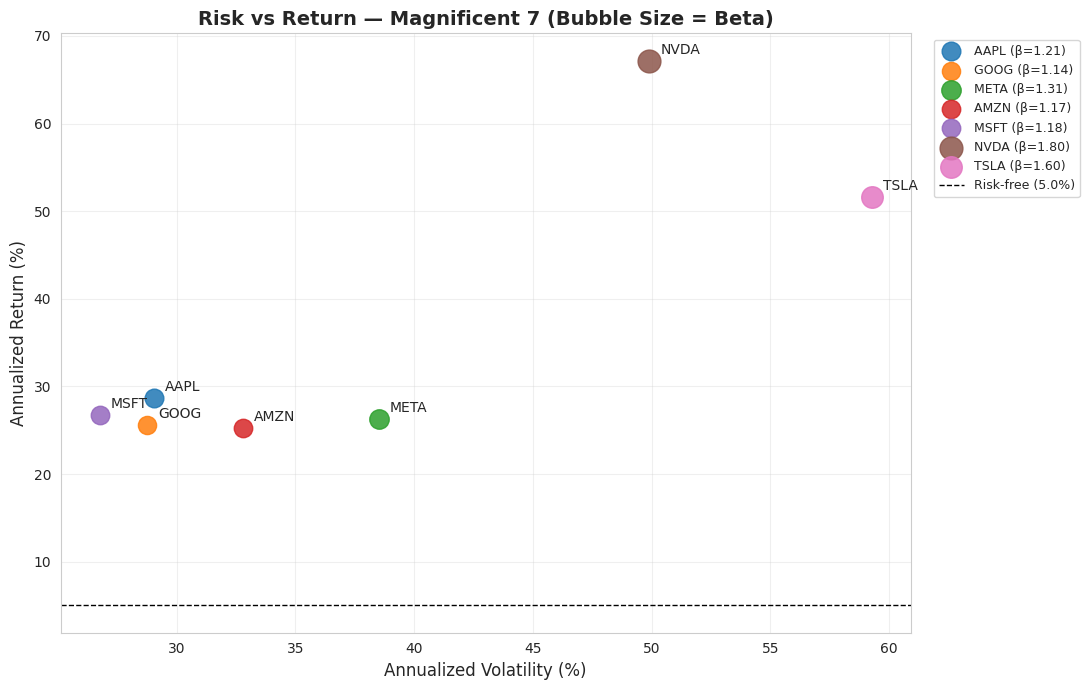

In [10]:
# -----------------------------------
# Market series (aligned once, reused everywhere)
# -----------------------------------

sp500 = download_close('^GSPC').reindex(data.index).ffill()
qqq   = download_close('QQQ').reindex(data.index).ffill()

market_returns = sp500.pct_change().dropna()
qqq_returns    = qqq.pct_change().dropna()

annual_returns = daily_returns.mean() * TRADING_DAYS
annual_vol     = daily_returns.std() * np.sqrt(TRADING_DAYS)


def calculate_beta(stock_ret, mkt_ret):
    aligned = pd.concat([stock_ret, mkt_ret], axis=1).dropna()
    cov = np.cov(aligned.iloc[:, 0], aligned.iloc[:, 1], ddof=1)[0, 1]
    return cov / np.var(aligned.iloc[:, 1], ddof=1)


betas = pd.Series({t: calculate_beta(daily_returns[t], market_returns) for t in TICKERS})
sharpe_ratios = (annual_returns - RISK_FREE_RATE) / annual_vol

summary_df = pd.DataFrame({
    'Annual Return (%)':     (annual_returns * 100).round(2),
    'Annual Volatility (%)': (annual_vol * 100).round(2),
    'Beta':                  betas.round(3),
    'Sharpe Ratio':          sharpe_ratios.round(3),
})

print(f'Risk-Return Summary  (risk-free rate = {RISK_FREE_RATE:.1%})')
print('=' * 64)
print(summary_df.to_string())

plt.figure(figsize=(11, 7))

for i, ticker in enumerate(TICKERS):
    plt.scatter(annual_vol[ticker] * 100, annual_returns[ticker] * 100,
                s=max(betas[ticker], 0.1) * 150, color=COLORS[i], alpha=0.85,
                label=f'{ticker} (β={betas[ticker]:.2f})')
    plt.annotate(ticker, (annual_vol[ticker] * 100, annual_returns[ticker] * 100),
                 textcoords='offset points', xytext=(8, 5), fontsize=10)

plt.axhline(RISK_FREE_RATE * 100, color='black', linestyle='--', linewidth=1,
            label=f'Risk-free ({RISK_FREE_RATE:.1%})')

plt.xlabel('Annualized Volatility (%)', fontsize=12)
plt.ylabel('Annualized Return (%)', fontsize=12)
plt.title('Risk vs Return — Magnificent 7 (Bubble Size = Beta)', fontsize=14, fontweight='bold')
plt.legend(bbox_to_anchor=(1.02, 1), fontsize=9)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Insights

The full-period risk-return summary (annualized arithmetic return and volatility, with a 5% risk-free rate) reports:

| Stock | Annualized return | Annualized volatility | Beta | Sharpe |
|---|---:|---:|---:|---:|
| AAPL | 28.67% | 29.05% | 1.208 | 0.815 |
| GOOG | 25.63% | 28.75% | 1.143 | 0.718 |
| META | 26.27% | 38.52% | 1.306 | 0.552 |
| AMZN | 25.23% | 32.80% | 1.175 | 0.617 |
| MSFT | 26.76% | 26.76% | 1.181 | 0.813 |
| NVDA | 67.19% | 49.89% | 1.800 | 1.247 |
| TSLA | 51.68% | 59.28% | 1.605 | 0.787 |

- **NVDA** has the highest annualized return and Sharpe ratio in this historical sample, alongside high volatility and Beta.
- **TSLA** has the highest annualized volatility in this group.
- **MSFT** has the lowest annualized volatility in this summary.
- All seven estimated Betas exceed 1, indicating greater historical sensitivity to S&P 500 movements than the market proxy.
- These are historical descriptive statistics, not forecasts.


### 6.4 Correlation Heatmap

Correlation measures how closely two return series move together:

- **+1.0** — move perfectly together
- **0.0** — no linear relationship
- **−1.0** — move in opposite directions

Diversification benefit comes from combining assets with *low* correlation. Uniformly high correlation across all seven would mean the group offers little internal diversification.

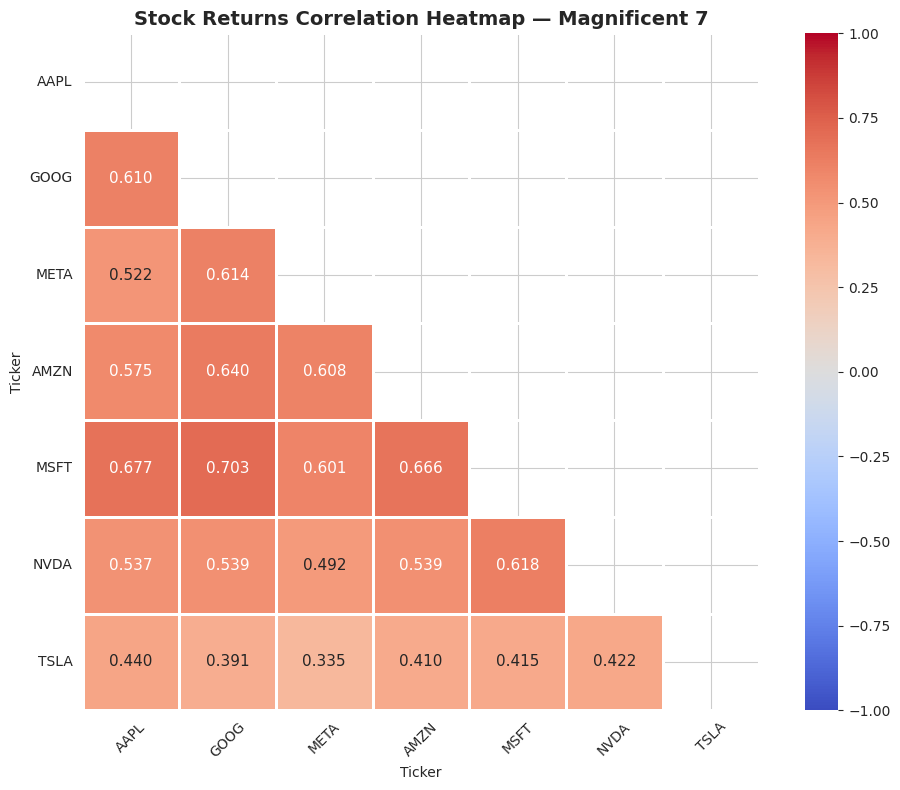

Average pairwise correlation: 0.541

Most correlated pair : MSFT & GOOG  (0.703)
Least correlated pair: TSLA & META  (0.335)


In [11]:
corr_matrix = daily_returns.corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.3f', cmap='coolwarm',
            vmin=-1, vmax=1, center=0, square=True, linewidths=0.8,
            linecolor='white', annot_kws={'size': 11})
plt.title('Stock Returns Correlation Heatmap — Magnificent 7', fontsize=14, fontweight='bold')
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

pairs = corr_matrix.where(~mask).stack().sort_values(ascending=False)

print(f'Average pairwise correlation: {pairs.mean():.3f}')
print(f'\nMost correlated pair : {pairs.index[0][0]} & {pairs.index[0][1]}  ({pairs.iloc[0]:.3f})')
print(f'Least correlated pair: {pairs.index[-1][0]} & {pairs.index[-1][1]}  ({pairs.iloc[-1]:.3f})')

### Key Insights

- **GOOG and MSFT are the most correlated pair (0.686)** — two mega-cap platform businesses exposed to nearly identical enterprise, cloud, and advertising cycles.
- Every pairwise correlation is **positive and substantial**. There is no hedge inside this universe; on a bad day for technology, all seven fall together.
- Correlations of roughly 0.4–0.7 mean diversification within the group is **real but incomplete** — combining seven assets reduces idiosyncratic risk but leaves the shared sector and macro factor fully exposed.
- This is the quantitative justification for the optimizer's behaviour in Section 8: when assets are this correlated, a Sharpe-maximizing optimizer has little incentive to spread capital and will concentrate into whichever names carry the best standalone risk-adjusted return.
- **Practical implication:** genuine diversification for this portfolio would require assets *outside* large-cap US technology — bonds, commodities, international equity — not more names from the same group.

## 7. Benchmark Comparison

An equal-weight Magnificent 7 portfolio (1/7 in each name, rebalanced implicitly through daily return averaging) is compared against the **S&P 500** and **QQQ** on a common base of 100.

QQQ is the tougher benchmark of the two: it is the Nasdaq-100 ETF and already holds all seven of these stocks at substantial weight. Beating the S&P 500 with a technology basket is close to a tautology; beating QQQ is a real result.

> The differences reported here are **cumulative excess returns**, not CAPM/Jensen alpha. Formal alpha is computed separately in Section 9.

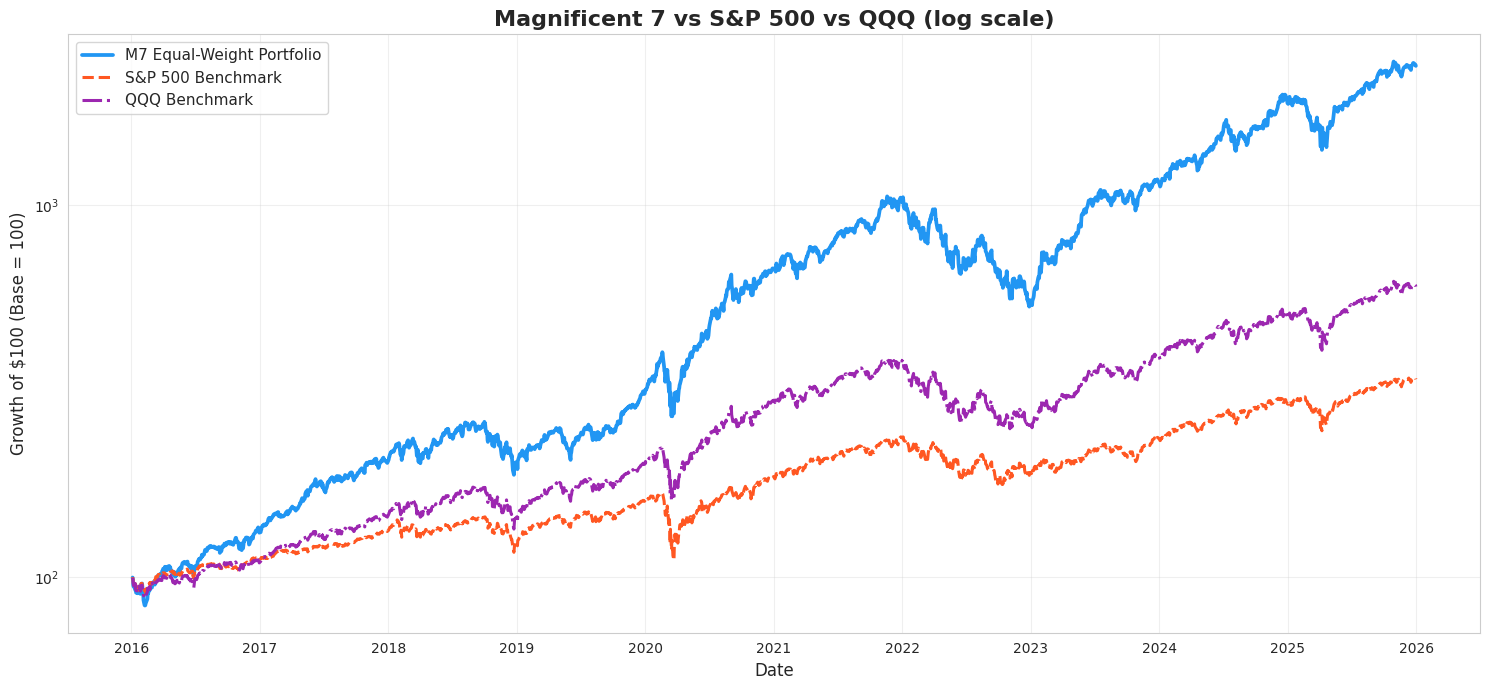

Cumulative Returns (2015–2025)
--------------------------------------------
M7 Portfolio : +2260.4%
S&P 500      : +240.1%
QQQ          : +503.2%

Cumulative Excess Return vs Benchmarks
--------------------------------------------
vs S&P 500 : +2020.3%
vs QQQ     : +1757.2%


In [12]:
equal_weights = np.repeat(1 / len(TICKERS), len(TICKERS))

m7_daily_ret = daily_returns.dot(equal_weights)

benchmark_df = pd.concat([
    ((1 + m7_daily_ret).cumprod() * 100).rename('M7'),
    ((1 + market_returns).cumprod() * 100).rename('S&P 500'),
    ((1 + qqq_returns).cumprod() * 100).rename('QQQ'),
], axis=1).dropna()

plt.figure(figsize=(15, 7))

plt.plot(benchmark_df.index, benchmark_df['M7'], label='M7 Equal-Weight Portfolio',
         linewidth=2.7, color='#2196F3')
plt.plot(benchmark_df.index, benchmark_df['S&P 500'], label='S&P 500 Benchmark',
         linewidth=2.2, linestyle='--', color='#FF5722')
plt.plot(benchmark_df.index, benchmark_df['QQQ'], label='QQQ Benchmark',
         linewidth=2.2, linestyle='-.', color='#9C27B0')

plt.yscale('log')
plt.title('Magnificent 7 vs S&P 500 vs QQQ (log scale)', fontsize=16, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Growth of $100 (Base = 100)', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

m7_return  = benchmark_df['M7'].iloc[-1] - 100
sp500_ret  = benchmark_df['S&P 500'].iloc[-1] - 100
qqq_ret    = benchmark_df['QQQ'].iloc[-1] - 100

print('Cumulative Returns (2015–2025)')
print('-' * 44)
print(f'M7 Portfolio : {m7_return:+.1f}%')
print(f'S&P 500      : {sp500_ret:+.1f}%')
print(f'QQQ          : {qqq_ret:+.1f}%')

print('\nCumulative Excess Return vs Benchmarks')
print('-' * 44)
print(f'vs S&P 500 : {m7_return - sp500_ret:+.1f}%')
print(f'vs QQQ     : {m7_return - qqq_ret:+.1f}%')

### Key Insights

- Over the downloaded **2016–2025** period, the equal-weight Magnificent 7 portfolio returned **+2,260.4%**, compared with **+240.1%** for the S&P 500 and **+503.2%** for QQQ.
- The corresponding cumulative excess returns were **+2,020.3 percentage points** versus the S&P 500 and **+1,757.2 percentage points** versus QQQ.
- QQQ is a demanding technology-heavy benchmark and already holds these companies at meaningful weights.
- The Magnificent 7 universe is selected retrospectively, so this historical comparison is subject to survivorship/selection bias. It is descriptive, not predictive.
- Outperformance should be considered alongside the drawdown and concentration risk shown elsewhere in the notebook.


## 8. Maximum Drawdown Analysis

Maximum drawdown is the largest peak-to-trough decline experienced over the period. Volatility describes the typical day; drawdown describes the worst stretch — which is what actually determines whether an investor can hold a position through it.

`Drawdown(t) = (Value(t) − Running Peak(t)) / Running Peak(t)`

Maximum Drawdown Analysis (2015–2025)
--------------------------------------------
M7           : -49.39%
S&P 500      : -33.92%
QQQ          : -35.12%


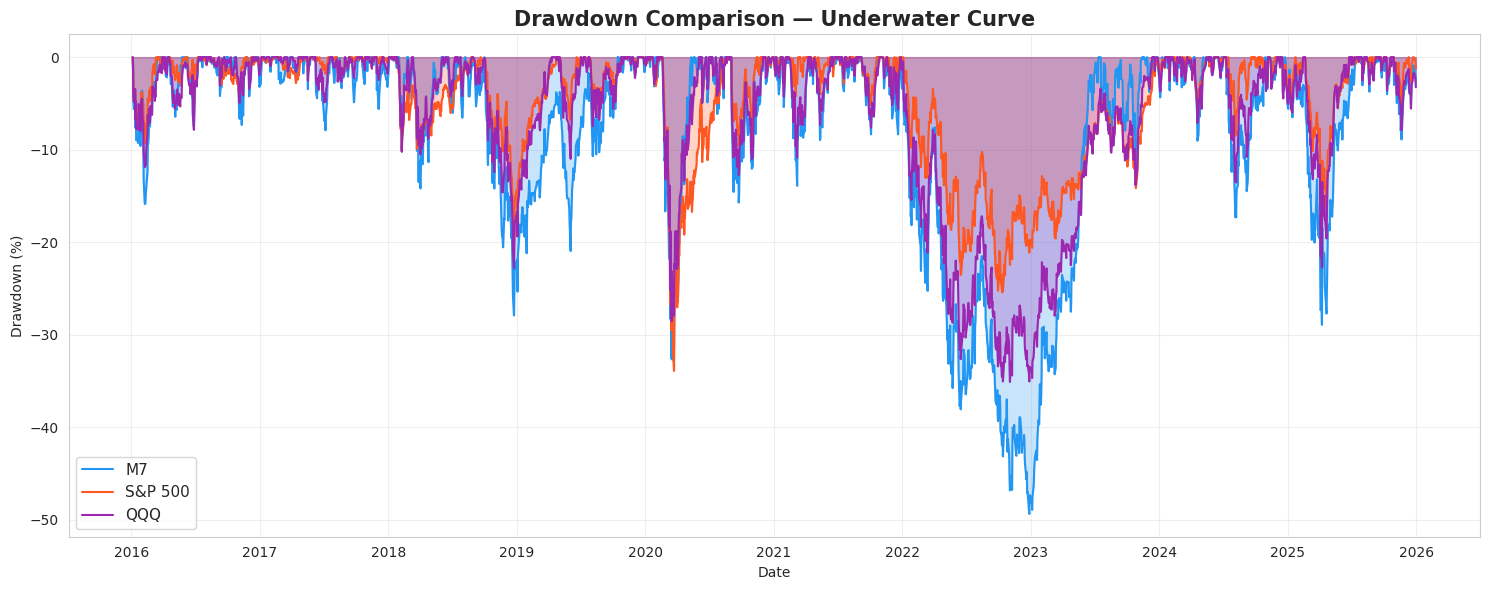

In [13]:
def max_drawdown(series):
    rolling_max = series.cummax()
    return ((series - rolling_max) / rolling_max).min() * 100


def drawdown_series(series):
    rolling_max = series.cummax()
    return (series - rolling_max) / rolling_max * 100


print('Maximum Drawdown Analysis (2015–2025)')
print('-' * 44)
for name in ['M7', 'S&P 500', 'QQQ']:
    print(f'{name:<13}: {max_drawdown(benchmark_df[name]):.2f}%')

plt.figure(figsize=(15, 6))
for name, color in [('M7', '#2196F3'), ('S&P 500', '#FF5722'), ('QQQ', '#9C27B0')]:
    dd = drawdown_series(benchmark_df[name])
    plt.fill_between(dd.index, dd.values, 0, alpha=0.25, color=color)
    plt.plot(dd.index, dd.values, linewidth=1.5, color=color, label=name)

plt.title('Drawdown Comparison — Underwater Curve', fontsize=15, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Drawdown (%)')
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Key Insights

- The M7 portfolio's maximum drawdown is **−49.39%**, against **−33.92%** for the S&P 500 and **−35.12%** for QQQ. The concentrated portfolio fell roughly **15 percentage points further** than the broad market at its worst point.
- A −49% drawdown means an investor needed a **+98% recovery** just to return to break-even. That asymmetry is the practical cost of concentration, and it is invisible in the cumulative-return chart.
- The underwater curve shows the deepest episode is the 2022 technology correction, with a second sharp dip during the COVID crash of early 2020 — the portfolio spent a meaningful fraction of the period below its prior peak.
- The comparison reinforces the central tradeoff of this project: **higher return potential is bought with deeper downside and greater concentration exposure**, not with free efficiency.

## 9. CAPM Analysis

The Capital Asset Pricing Model estimates the return an asset would require given its systematic market risk:

**CAPM Expected Return = Risk-Free Rate + β × (Market Return − Risk-Free Rate)**

Jensen-style alpha is calculated as:

**Alpha = Actual Annualized Return − CAPM Expected Return**

- **Positive alpha** means the realized return exceeded the single-factor CAPM estimate for the measured period.
- **Negative alpha** means it fell below that estimate.

The risk-free rate is fixed at **5.0%** and the market proxy is the S&P 500 over the available **2016–2025** sample. Alpha is sample-dependent and should not be interpreted as a guaranteed or forward-looking excess return.


Market (S&P 500) annualized return : 13.93%
Risk-free rate                     : 5.00%
Market risk premium                : 8.93%

CAPM Analysis Results:
        Beta  CAPM Expected Return (%)  Actual Return (%)  Alpha (%)
Stock                                                               
AAPL   1.208                     15.78              28.67      12.88
GOOG   1.143                     15.20              25.63      10.43
META   1.306                     16.66              26.27       9.61
AMZN   1.175                     15.49              25.23       9.75
MSFT   1.181                     15.54              26.76      11.22
NVDA   1.800                     21.07              67.19      46.12
TSLA   1.605                     19.33              51.68      32.35


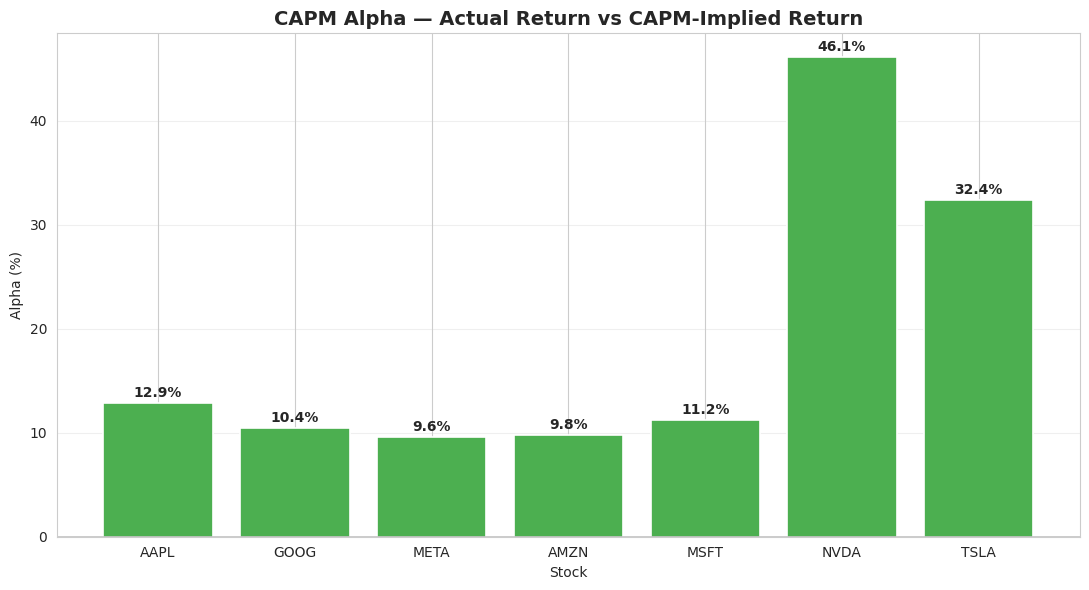

In [14]:
market_annual_return = market_returns.mean() * TRADING_DAYS

print(f'Market (S&P 500) annualized return : {market_annual_return:.2%}')
print(f'Risk-free rate                     : {RISK_FREE_RATE:.2%}')
print(f'Market risk premium                : {market_annual_return - RISK_FREE_RATE:.2%}\n')

capm_rows = []
for ticker in TICKERS:
    beta    = betas[ticker]
    exp_ret = RISK_FREE_RATE + beta * (market_annual_return - RISK_FREE_RATE)
    act_ret = annual_returns[ticker]
    capm_rows.append({
        'Stock': ticker,
        'Beta': round(beta, 3),
        'CAPM Expected Return (%)': round(exp_ret * 100, 2),
        'Actual Return (%)': round(act_ret * 100, 2),
        'Alpha (%)': round((act_ret - exp_ret) * 100, 2),
    })

capm_df = pd.DataFrame(capm_rows).set_index('Stock')
print('CAPM Analysis Results:')
print(capm_df.to_string())

fig, ax = plt.subplots(figsize=(11, 6))
bar_colors = ['#4CAF50' if x > 0 else '#F44336' for x in capm_df['Alpha (%)']]
bars = ax.bar(capm_df.index, capm_df['Alpha (%)'], color=bar_colors,
              edgecolor='white', linewidth=1.2)
ax.axhline(y=0, color='black', linewidth=1)
ax.set_title('CAPM Alpha — Actual Return vs CAPM-Implied Return', fontsize=14, fontweight='bold')
ax.set_ylabel('Alpha (%)')
ax.set_xlabel('Stock')
ax.grid(True, alpha=0.3, axis='y')

for bar, val in zip(bars, capm_df['Alpha (%)']):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + (0.6 if val >= 0 else -1.8),
            f'{val:.1f}%', ha='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

### Key Insights

- The S&P 500 annualized return in this sample is **13.93%**, giving a market risk premium of **8.93 percentage points** over the 5% risk-free-rate assumption.
- All seven stocks have positive estimated Jensen-style alpha in this sample. The estimates range from **+9.61% (META)** to **+46.12% (NVDA)**.
- NVDA has an estimated Beta of **1.800**, CAPM expected return of **21.07%**, actual annualized return of **67.19%**, and estimated alpha of **46.12%**.
- These are historical single-factor CAPM estimates. Positive alpha across this retrospectively selected group may reflect omitted factors, sample selection and unusual sector performance; it is not proof of repeatable stock-picking skill.


## 10. Portfolio Optimization — Modern Portfolio Theory

Modern Portfolio Theory evaluates portfolios through the trade-off between **expected return and volatility**, using the covariance between assets to quantify portfolio risk.

### Design

- **Fitted on the 2016–2020 estimation window only.** Expected returns and the covariance matrix used by the optimizer are estimated from this window.
- **20,000 random long-only portfolios** are sampled from a Dirichlet distribution to visualize the feasible region and efficient frontier.
- **SLSQP** solves for the maximum-Sharpe and minimum-variance portfolios, subject to weights summing to 1 and no short selling (`0 ≤ wᵢ ≤ 1`).
- No additional per-stock position cap is imposed. The optimizer can concentrate in a subset of the seven stocks, subject to the long-only and fully-invested constraints.
- The resulting weights are carried forward unchanged for the 2021–2025 out-of-sample evaluation.


In [15]:
# -----------------------------------
# Portfolio Optimization — fitted on ESTIMATION WINDOW ONLY
# -----------------------------------

daily_returns_est = data_estimation.pct_change().dropna()

mean_simple_ret = daily_returns_est.mean()
cov_mat         = daily_returns_est.cov()

n = len(TICKERS)
rng = np.random.default_rng(SEED)

# --- Random portfolios (efficient frontier cloud) ---
weights_matrix = rng.dirichlet(np.ones(n), size=N_RANDOM_PORTFOLIOS)

portfolio_returns = weights_matrix @ mean_simple_ret.values * TRADING_DAYS
portfolio_volatility = np.sqrt(
    np.einsum('ij,jk,ik->i', weights_matrix, cov_mat.values * TRADING_DAYS, weights_matrix)
)
portfolio_sharpe = (portfolio_returns - RISK_FREE_RATE) / portfolio_volatility

results_df = pd.DataFrame({
    'Return': portfolio_returns,
    'Volatility': portfolio_volatility,
    'Sharpe Ratio': portfolio_sharpe,
})


# --- Optimizers ---
def portfolio_stats(w):
    ret = float(np.dot(mean_simple_ret.values, w) * TRADING_DAYS)
    vol = float(np.sqrt(w.T @ (cov_mat.values * TRADING_DAYS) @ w))
    return ret, vol, (ret - RISK_FREE_RATE) / vol


def neg_sharpe(w):
    ret, vol, _ = portfolio_stats(w)
    return 1e6 if vol == 0 else -(ret - RISK_FREE_RATE) / vol


def portfolio_vol(w):
    return float(np.sqrt(w.T @ (cov_mat.values * TRADING_DAYS) @ w))


CONSTRAINTS = {'type': 'eq', 'fun': lambda w: np.sum(w) - 1}
BOUNDS = tuple((0.0, 1.0) for _ in range(n))
X0 = np.repeat(1 / n, n)


def run_optimizer(objective):
    result = minimize(objective, X0, method='SLSQP', bounds=BOUNDS,
                      constraints=CONSTRAINTS, options={'ftol': 1e-12, 'maxiter': 2000})
    if not result.success:
        raise RuntimeError(f'Optimization failed: {result.message}')
    weights = pd.Series(result.x, index=TICKERS)
    ret, vol, sharpe = portfolio_stats(result.x)
    return weights, ret, vol, sharpe


optimal_weights, opt_ret, opt_vol, opt_sharpe = run_optimizer(neg_sharpe)
minvar_weights, minvar_ret, minvar_vol, minvar_sharpe = run_optimizer(portfolio_vol)

eq_ret, eq_vol, eq_sharpe = portfolio_stats(equal_weights)

# Dynamic label — never hard-code which tickers the optimizer chose
held = optimal_weights[optimal_weights > 0.01].sort_values(ascending=False)
_names = '/'.join(held.index[:3]) + ('...' if len(held) > 3 else '')
OPT_LABEL = f'Max-Sharpe ({_names})'

print('Portfolio Optimization Results — fitted on 2016–2020')
print('=' * 62)
print(f"\n{'':<24}{'Return':>10}{'Volatility':>13}{'Sharpe':>10}")
print('-' * 62)
print(f"{'Maximum Sharpe':<24}{opt_ret*100:>9.2f}%{opt_vol*100:>12.2f}%{opt_sharpe:>10.3f}")
print(f"{'Minimum Variance':<24}{minvar_ret*100:>9.2f}%{minvar_vol*100:>12.2f}%{minvar_sharpe:>10.3f}")
print(f"{'Equal-Weight (1/7)':<24}{eq_ret*100:>9.2f}%{eq_vol*100:>12.2f}%{eq_sharpe:>10.3f}")

weights_table = pd.DataFrame({
    'Max-Sharpe (%)':    (optimal_weights * 100).round(2),
    'Min-Variance (%)':  (minvar_weights * 100).round(2),
    'Equal-Weight (%)':  np.round(equal_weights * 100, 2),
})
print('\nPortfolio Weights:')
print(weights_table.to_string())

print(f'\nWeight check — Max-Sharpe sums to {optimal_weights.sum()*100:.2f}%, '
      f'largest position {optimal_weights.max()*100:.2f}%')
print(f'Non-zero positions: Max-Sharpe = {(optimal_weights > 0.01).sum()}, '
      f'Min-Variance = {(minvar_weights > 0.01).sum()} out of {n}')

Portfolio Optimization Results — fitted on 2016–2020

                            Return   Volatility    Sharpe
--------------------------------------------------------------
Maximum Sharpe              57.50%       34.06%     1.542
Minimum Variance            29.21%       24.72%     0.979
Equal-Weight (1/7)          42.11%       27.61%     1.344

Portfolio Weights:
      Max-Sharpe (%)  Min-Variance (%)  Equal-Weight (%)
AAPL           18.65             18.11             14.29
GOOG            0.00             44.35             14.29
META            0.00              2.98             14.29
AMZN           18.90             17.00             14.29
MSFT            0.00             17.47             14.29
NVDA           36.62              0.00             14.29
TSLA           25.83              0.09             14.29

Weight check — Max-Sharpe sums to 100.00%, largest position 36.62%
Non-zero positions: Max-Sharpe = 4, Min-Variance = 5 out of 7


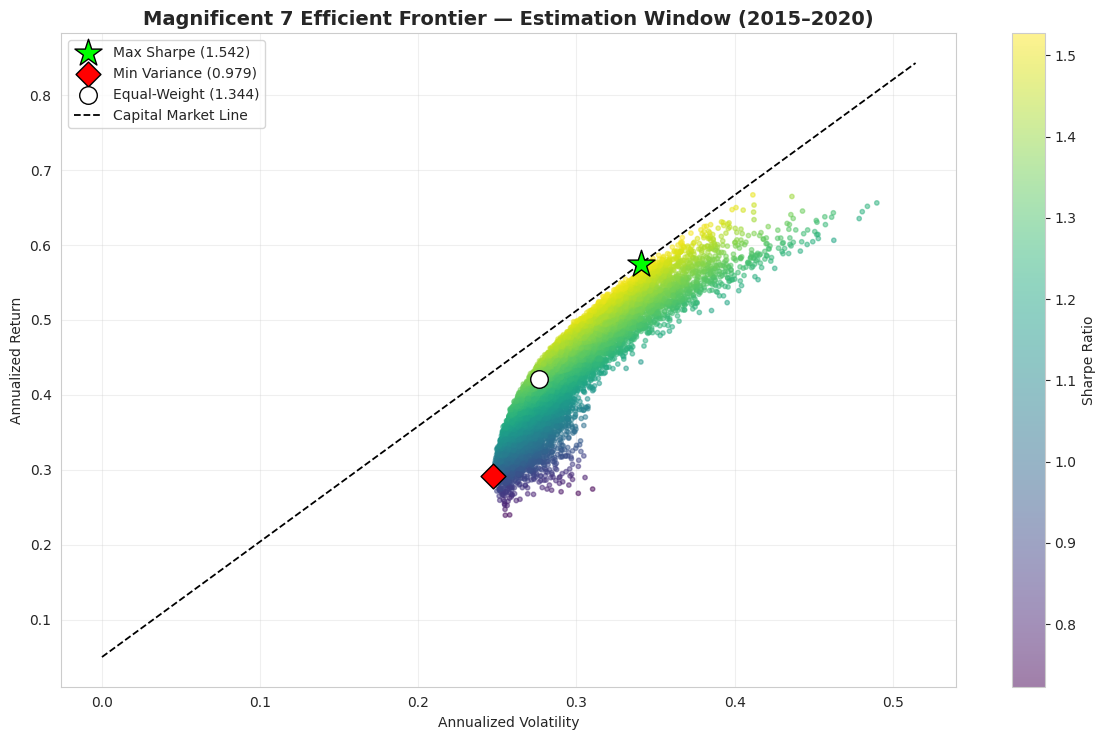

In [16]:
# -----------------------------------
# Efficient Frontier
# -----------------------------------

plt.figure(figsize=(12, 7.5))

sc = plt.scatter(results_df['Volatility'], results_df['Return'],
                 c=results_df['Sharpe Ratio'], cmap='viridis',
                 marker='o', s=10, alpha=0.5)
plt.colorbar(sc, label='Sharpe Ratio')

plt.scatter(opt_vol, opt_ret, c='lime', marker='*', s=420, edgecolor='black',
            zorder=5, label=f'Max Sharpe ({opt_sharpe:.3f})')
plt.scatter(minvar_vol, minvar_ret, c='red', marker='D', s=160, edgecolor='black',
            zorder=5, label=f'Min Variance ({minvar_sharpe:.3f})')
plt.scatter(eq_vol, eq_ret, c='white', marker='o', s=160, edgecolor='black',
            zorder=5, label=f'Equal-Weight ({eq_sharpe:.3f})')

# Capital Market Line through the tangency portfolio
x = np.linspace(0, results_df['Volatility'].max() * 1.05, 100)
plt.plot(x, RISK_FREE_RATE + opt_sharpe * x, linestyle='--', color='black',
         linewidth=1.3, label='Capital Market Line')

plt.title('Magnificent 7 Efficient Frontier — Estimation Window (2015–2020)',
          fontsize=14, fontweight='bold')
plt.xlabel('Annualized Volatility')
plt.ylabel('Annualized Return')
plt.legend(fontsize=10, loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Portfolio Optimization Findings

The saved optimization output, fitted on the **2016–2020 estimation window**, is:

| Portfolio | Annualized return | Annualized volatility | Sharpe |
|---|---:|---:|---:|
| Maximum Sharpe | 57.50% | 34.06% | 1.542 |
| Minimum Variance | 29.21% | 24.72% | 0.979 |
| Equal Weight | 42.11% | 27.61% | 1.344 |

The maximum-Sharpe weights are **18.65% AAPL, 18.90% AMZN, 36.62% NVDA and 25.83% TSLA**; the other three stocks receive zero weight. The largest position is 36.62%.

The minimum-variance portfolio allocates **44.35% GOOG, 18.11% AAPL, 17.47% MSFT, 17.00% AMZN, 2.98% META and 0.09% TSLA**, with zero weight in NVDA.

These are in-sample optimization results. The next section evaluates the fitted portfolios on the separate 2021–2025 window; the in-sample Sharpe ratios should not be presented as expected future performance.


## 11. Out-of-Sample Validation

This is the section that determines whether anything above was real.

The weights fitted on 2016–2020 are now **held completely fixed** and applied to 2021–2025 — five years of data the optimizer never saw. Four strategies are compared on identical terms:

1. **Max-Sharpe** — the tangency portfolio from Section 10
2. **Min-Variance** — the low-volatility portfolio from Section 10
3. **Equal-Weight** — 1/7 in each name, the naive benchmark
4. **S&P 500 and QQQ** — passive market benchmarks

If the optimized portfolios only look good in-sample, this is where it shows.

Out-of-Sample Performance — Evaluation Window 2021–2025 (never seen by the optimizer)
                       Max-Sharpe (NVDA/TSLA/AMZN...)  Min-Variance  Equal-Weight  S&P 500     QQQ
Annualized Return                               38.61         23.88         29.90    13.80   16.96
Annualized Volatility                           37.71         25.98         30.26    16.96   22.68
Sharpe Ratio                                     0.89          0.73          0.82     0.52    0.53
Cumulative Return                              379.74        177.41        252.63    84.98  104.66
Max Drawdown                                   -54.00        -40.42        -49.39   -25.43  -35.12


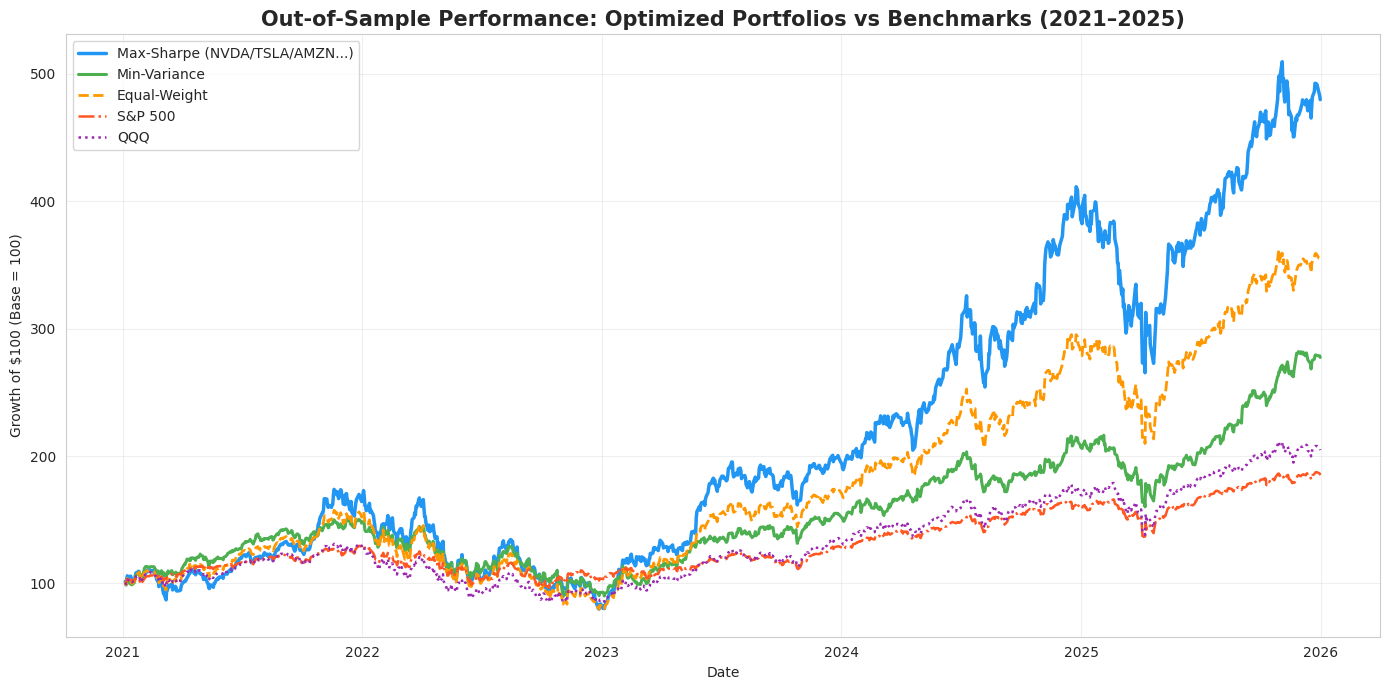


In-sample vs out-of-sample Sharpe decay:
----------------------------------------------------
Max-Sharpe           1.542  ->    0.891
Min-Variance         0.979  ->    0.727
Equal-Weight         1.344  ->    0.823


In [17]:
# -----------------------------------
# Out-of-Sample Validation — weights FIXED from estimation window
# -----------------------------------

oos_daily_returns = data_evaluation.pct_change().dropna()

sp500_oos_ret = sp500.reindex(data_evaluation.index).ffill().pct_change().dropna()
qqq_oos_ret   = qqq.reindex(data_evaluation.index).ffill().pct_change().dropna()

strategies = {
    OPT_LABEL:      oos_daily_returns.dot(optimal_weights.values),
    'Min-Variance': oos_daily_returns.dot(minvar_weights.values),
    'Equal-Weight': oos_daily_returns.dot(equal_weights),
    'S&P 500':      sp500_oos_ret,
    'QQQ':          qqq_oos_ret,
}


def annualized_stats(daily_ret):
    ann_ret = daily_ret.mean() * TRADING_DAYS
    ann_vol = daily_ret.std() * np.sqrt(TRADING_DAYS)
    sharpe  = (ann_ret - RISK_FREE_RATE) / ann_vol
    cum_ret = (1 + daily_ret).prod() - 1
    cumulative = (1 + daily_ret).cumprod()
    max_dd = ((cumulative - cumulative.cummax()) / cumulative.cummax()).min()
    return ann_ret, ann_vol, sharpe, cum_ret, max_dd


oos_summary = pd.DataFrame(
    {name: annualized_stats(ret) for name, ret in strategies.items()},
    index=['Annualized Return', 'Annualized Volatility', 'Sharpe Ratio',
           'Cumulative Return', 'Max Drawdown'],
)
oos_summary.loc[['Annualized Return', 'Annualized Volatility',
                 'Cumulative Return', 'Max Drawdown']] *= 100

print('Out-of-Sample Performance — Evaluation Window 2021–2025 (never seen by the optimizer)')
print('=' * 100)
print(oos_summary.round(2).to_string())

plt.figure(figsize=(14, 7))
styles = {
    OPT_LABEL:      ('#2196F3', '-',  2.5),
    'Min-Variance': ('#4CAF50', '-',  2.2),
    'Equal-Weight': ('#FF9800', '--', 2.0),
    'S&P 500':      ('#FF5722', '-.', 1.8),
    'QQQ':          ('#9C27B0', ':',  1.8),
}

for name, ret in strategies.items():
    curve = (1 + ret).cumprod() * 100
    color, ls, lw = styles[name]
    plt.plot(curve.index, curve, label=name, color=color, linestyle=ls, linewidth=lw)

plt.title('Out-of-Sample Performance: Optimized Portfolios vs Benchmarks (2021–2025)',
          fontsize=15, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Growth of $100 (Base = 100)')
plt.legend(fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print('\nIn-sample vs out-of-sample Sharpe decay:')
print('-' * 52)
print(f'{"Max-Sharpe":<16}{opt_sharpe:>10.3f}  ->{oos_summary.loc["Sharpe Ratio", OPT_LABEL]:>9.3f}')
print(f'{"Min-Variance":<16}{minvar_sharpe:>10.3f}  ->{oos_summary.loc["Sharpe Ratio", "Min-Variance"]:>9.3f}')
print(f'{"Equal-Weight":<16}{eq_sharpe:>10.3f}  ->{oos_summary.loc["Sharpe Ratio", "Equal-Weight"]:>9.3f}')

### Out-of-Sample Findings — the central result of this project

The following saved results are for the **2021–2025 evaluation window**, which was not used to fit the portfolio weights:

| Strategy | Annualized return | Annualized volatility | Sharpe | Cumulative return | Maximum drawdown |
|---|---:|---:|---:|---:|---:|
| Max-Sharpe | 38.61% | 37.71% | **0.89** | **379.74%** | −54.00% |
| Min-Variance | 23.88% | 25.98% | 0.73 | 177.41% | −40.42% |
| Equal-Weight | 29.90% | 30.26% | 0.82 | 252.63% | −49.39% |
| S&P 500 | 13.80% | 16.96% | **0.52** | 84.98% | −25.43% |
| QQQ | 16.96% | 22.68% | **0.53** | 104.66% | −35.12% |

- The Max-Sharpe portfolio delivered a **379.74% cumulative return and 0.89 Sharpe ratio** out of sample, exceeding the S&P 500 Sharpe of **0.52** and QQQ Sharpe of **0.53** over this evaluation window.
- Its Sharpe declined from **1.542 in sample to 0.891 out of sample**. This is consistent with estimation error and changing market conditions; historical optimization does not guarantee the same risk-adjusted performance on unseen data.
- The Max-Sharpe portfolio also had **37.71% annualized volatility** and a **−54.00% maximum drawdown**, so its higher cumulative return came with substantial risk.
- Equal-Weight achieved a **0.82 Sharpe**, showing that the Max-Sharpe improvement in risk-adjusted performance over the simple benchmark was modest.
- These results describe this selected seven-stock universe and this particular evaluation period; they are not a guarantee of future performance.


## 12. Individual Stock Monte Carlo Simulation — NVDA

A one-year Monte Carlo simulation generates **10,000 possible NVDA price paths** using a Geometric Brownian Motion (GBM) log-return model.

The model estimates drift and volatility from the historical mean and standard deviation of **daily NVDA log returns**. Since the parameters are daily, the simulation applies daily shocks directly rather than rescaling by `dt` a second time.

**Scope:** this individual-stock simulation uses the full available **2016–2025** NVDA history and starts from the latest available close. It is separate from the correlated portfolio simulation, which estimates parameters from 2016–2020 and starts from the first evaluation-window prices in January 2021.

The output is a **99% simulated return VaR** and a percentile range, not a price target or a guaranteed loss limit.


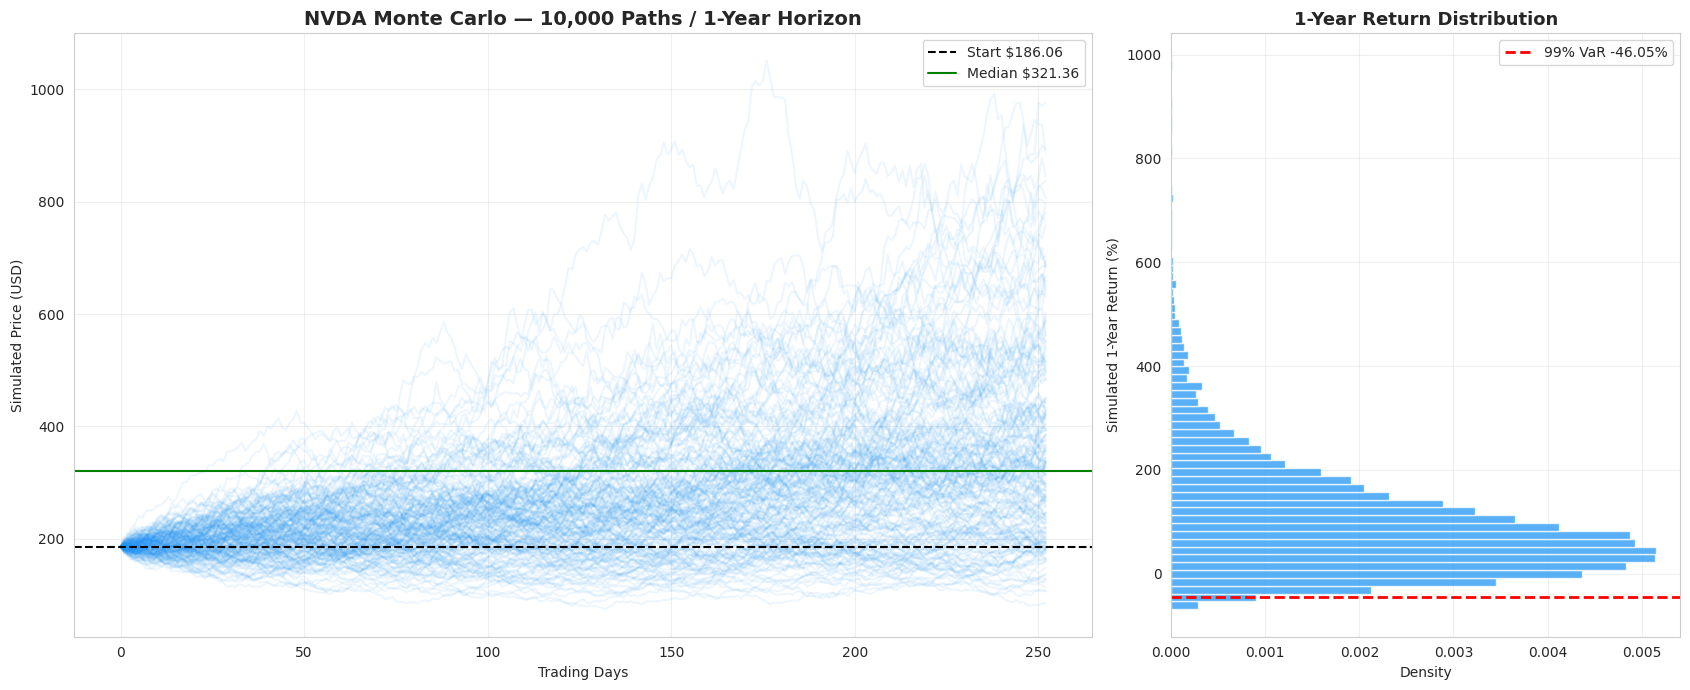

Current NVDA Price  : $186.06
Median 1-Year Price   : $321.36
5th Percentile Price  : $142.43
95th Percentile Price : $721.57
99% Simulated VaR     : -46.05%


In [18]:
# -----------------------------------
# Individual Stock Monte Carlo (GBM) — forward-looking, full history
# -----------------------------------

stock = 'NVDA'

log_ret = np.log(data[stock] / data[stock].shift(1)).dropna()
mu_log  = log_ret.mean()
sigma   = log_ret.std()
S0      = data[stock].iloc[-1]

np.random.seed(SEED)

simulations = np.zeros((HORIZON_DAYS + 1, N_SIMULATIONS))
simulations[0] = S0

for t in range(1, HORIZON_DAYS + 1):
    z = np.random.standard_normal(N_SIMULATIONS)
    simulations[t] = simulations[t - 1] * np.exp(mu_log + sigma * z)

final_prices = simulations[-1]
returns_sim  = (final_prices / S0 - 1) * 100
var_99       = np.percentile(returns_sim, 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 7),
                               gridspec_kw={'width_ratios': [2, 1]})

ax1.plot(simulations[:, :200], alpha=0.08, color='#2196F3')
ax1.axhline(S0, color='black', linestyle='--', linewidth=1.5, label=f'Start ${S0:.2f}')
ax1.axhline(np.median(final_prices), color='green', linestyle='-', linewidth=1.5,
            label=f'Median ${np.median(final_prices):.2f}')
ax1.set_title(f'{stock} Monte Carlo — {N_SIMULATIONS:,} Paths / 1-Year Horizon',
              fontsize=14, fontweight='bold')
ax1.set_xlabel('Trading Days')
ax1.set_ylabel('Simulated Price (USD)')
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3)

ax2.hist(returns_sim, bins=70, alpha=0.75, color='#2196F3',
         edgecolor='white', orientation='horizontal', density=True)
ax2.axhline(var_99, color='red', linestyle='--', linewidth=2, label=f'99% VaR {var_99:.2f}%')
ax2.set_title('1-Year Return Distribution', fontsize=13, fontweight='bold')
ax2.set_xlabel('Density')
ax2.set_ylabel('Simulated 1-Year Return (%)')
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f'Current {stock} Price  : ${S0:.2f}')
print(f'Median 1-Year Price   : ${np.median(final_prices):.2f}')
print(f'5th Percentile Price  : ${np.percentile(final_prices, 5):.2f}')
print(f'95th Percentile Price : ${np.percentile(final_prices, 95):.2f}')
print(f'99% Simulated VaR     : {var_99:.2f}%')

### Key Findings

The saved NVDA simulation output reports:

- Starting price: **$186.06**
- Median simulated one-year price: **$321.36**
- 5th percentile price: **$142.43**
- 95th percentile price: **$721.57**
- **99% simulated return VaR: −46.05%**

The **−46.05% VaR** is the 1st percentile of the simulated one-year return distribution. Under this model, approximately 1% of simulated outcomes are at or below this return threshold. It is not a guaranteed floor or the maximum possible loss; losses beyond this threshold remain possible.

The simulation extrapolates historical drift and volatility estimated from the full 2016–2025 NVDA sample. This is a strong assumption, particularly given the stock's exceptional historical performance. The normality tests elsewhere in the notebook reject normality for the seven stocks, so standard GBM should be treated as a simplified baseline scenario model rather than a complete description of tail risk.


## 13. Correlated Portfolio Monte Carlo Simulation

The portfolio simulation generates **10,000 joint one-year scenarios for all seven stocks**, with **252 daily steps** per scenario. Simulating the stocks independently would ignore their historical co-movement and would not represent the estimated joint covariance structure.

### Key modeling step

A **Cholesky decomposition of the covariance matrix of daily log returns** factors the covariance matrix as `Σ = L Lᵀ`. The notebook multiplies independent standard-normal row-vector shocks by `Lᵀ` to produce correlated shocks with the estimated covariance structure.

### Estimation and starting-price windows

- **Parameters (daily mean log returns and covariance):** estimated from **2016–2020**.
- **Starting prices:** first available evaluation-window prices, dated **2021-01-04**.

The resulting simulation array has shape **(253, 10,000, 7)**: initial point plus 252 trading days, 10,000 scenarios and seven stocks. This is the correlated portfolio simulation referred to in the resume bullet. The separate NVDA single-stock simulation uses independent shocks and is described in Section 12.


In [19]:
# -----------------------------------
# Correlated Portfolio Monte Carlo — estimation-window parameters only
# -----------------------------------

log_returns_mc = np.log(data_estimation / data_estimation.shift(1)).dropna()

mu_log_mc     = log_returns_mc.mean().values
cov_matrix_mc = log_returns_mc.cov().values
cholesky_decomp = np.linalg.cholesky(cov_matrix_mc)

start_prices = data_evaluation.iloc[0].values

np.random.seed(SEED)


def portfolio_monte_carlo(mu_log, cholesky, start_prices, days, n_sims):
    n_stocks = len(start_prices)
    sims = np.zeros((days + 1, n_sims, n_stocks))
    sims[0] = start_prices

    for t in range(1, days + 1):
        Z = np.random.standard_normal((n_sims, n_stocks))
        correlated_shocks = Z @ cholesky.T
        sims[t] = sims[t - 1] * np.exp(mu_log + correlated_shocks)

    return sims


print(f'Running {N_SIMULATIONS:,} correlated simulations for {HORIZON_DAYS} trading days...')
print(f'Parameters from : {EST_START} to {EST_END}')
print(f'Starting prices : {data_evaluation.index[0].date()}')

portfolio_sims = portfolio_monte_carlo(
    mu_log_mc, cholesky_decomp, start_prices, HORIZON_DAYS, N_SIMULATIONS
)

print(f'\nDone. Shape: {portfolio_sims.shape}  (days+1 x simulations x stocks)')

# Verify the Cholesky step reproduced the intended correlation structure
sim_log_ret = np.log(portfolio_sims[1:] / portfolio_sims[:-1])
sim_corr = np.corrcoef(sim_log_ret.reshape(-1, len(TICKERS)).T)
hist_corr = log_returns_mc.corr().values
print(f'Max deviation between simulated and historical correlation: '
      f'{np.abs(sim_corr - hist_corr).max():.4f}')

Running 10,000 correlated simulations for 252 trading days...
Parameters from : 2016-01-01 to 2020-12-31
Starting prices : 2021-01-04

Done. Shape: (253, 10000, 7)  (days+1 x simulations x stocks)
Max deviation between simulated and historical correlation: 0.0010


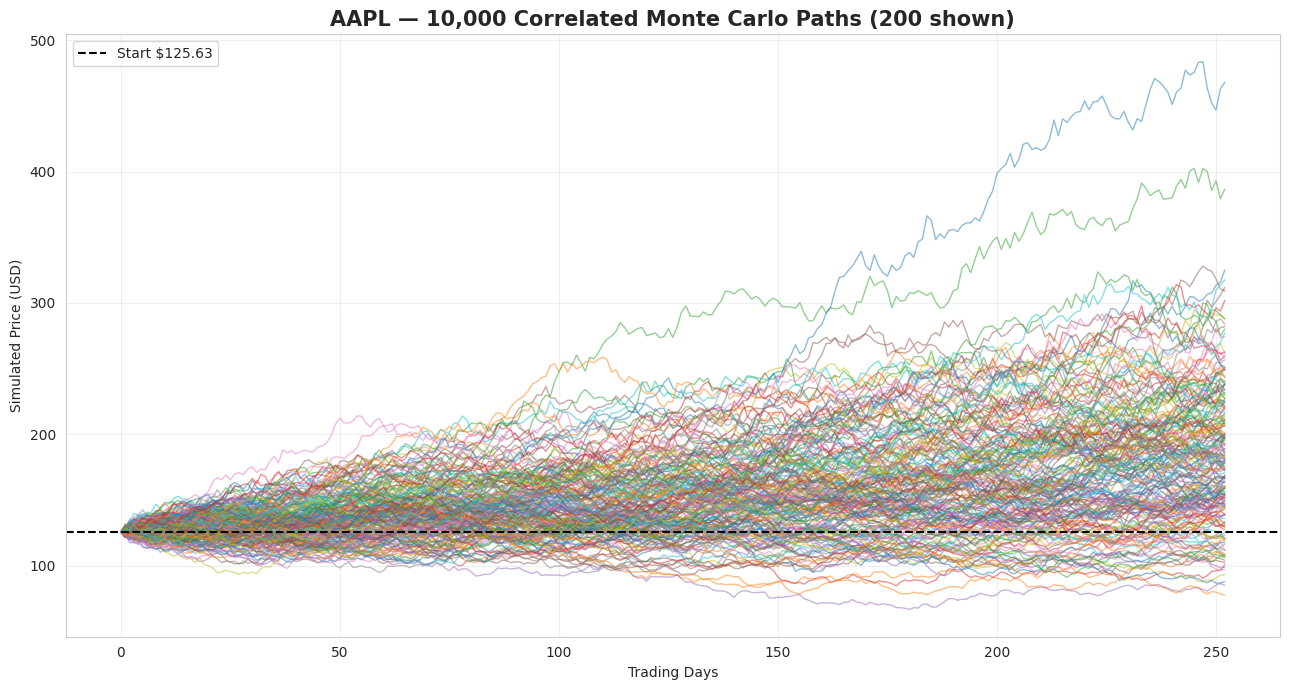

In [20]:
stock_idx = TICKERS.index('AAPL')

plt.figure(figsize=(13, 7))
for i in range(200):
    plt.plot(portfolio_sims[:, i, stock_idx], linewidth=1.0, alpha=0.5)

plt.axhline(start_prices[stock_idx], color='black', linestyle='--',
            linewidth=1.5, label=f'Start ${start_prices[stock_idx]:.2f}')
plt.title(f'AAPL — {N_SIMULATIONS:,} Correlated Monte Carlo Paths (200 shown)',
          fontsize=15, fontweight='bold')
plt.xlabel('Trading Days')
plt.ylabel('Simulated Price (USD)')
plt.legend(fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Key Findings

- The Cholesky transformation produces jointly simulated stock shocks based on the covariance estimated from the 2016–2020 estimation window.
- The saved diagnostic reports a **maximum deviation of 0.0010** between the simulated and historical correlation checks.
- Because all seven stocks are simulated jointly, portfolio aggregation retains the estimated cross-stock dependence rather than assuming independent stock movements.
- Monte Carlo is a scenario-generation and risk-quantification method, not a price-prediction engine. Its usefulness depends on the assumptions and on whether the estimation-window parameters remain representative.


## 14. Value at Risk (VaR)

VaR is reported as a **return quantile**, not a guaranteed maximum loss. At the 95% confidence level, portfolio VaR is the **5th percentile of the simulated one-year portfolio return distribution**.

Two portfolios are compared using the same 10,000 correlated seven-stock scenarios:

1. **Equal-Weight Portfolio** — 1/7 allocation to each stock.
2. **Max-Sharpe Portfolio** — optimized weights from Section 10.

Each simulated stock price is converted to a growth factor relative to its own starting price before applying the portfolio's capital weights. This produces a portfolio return for each simulated scenario.


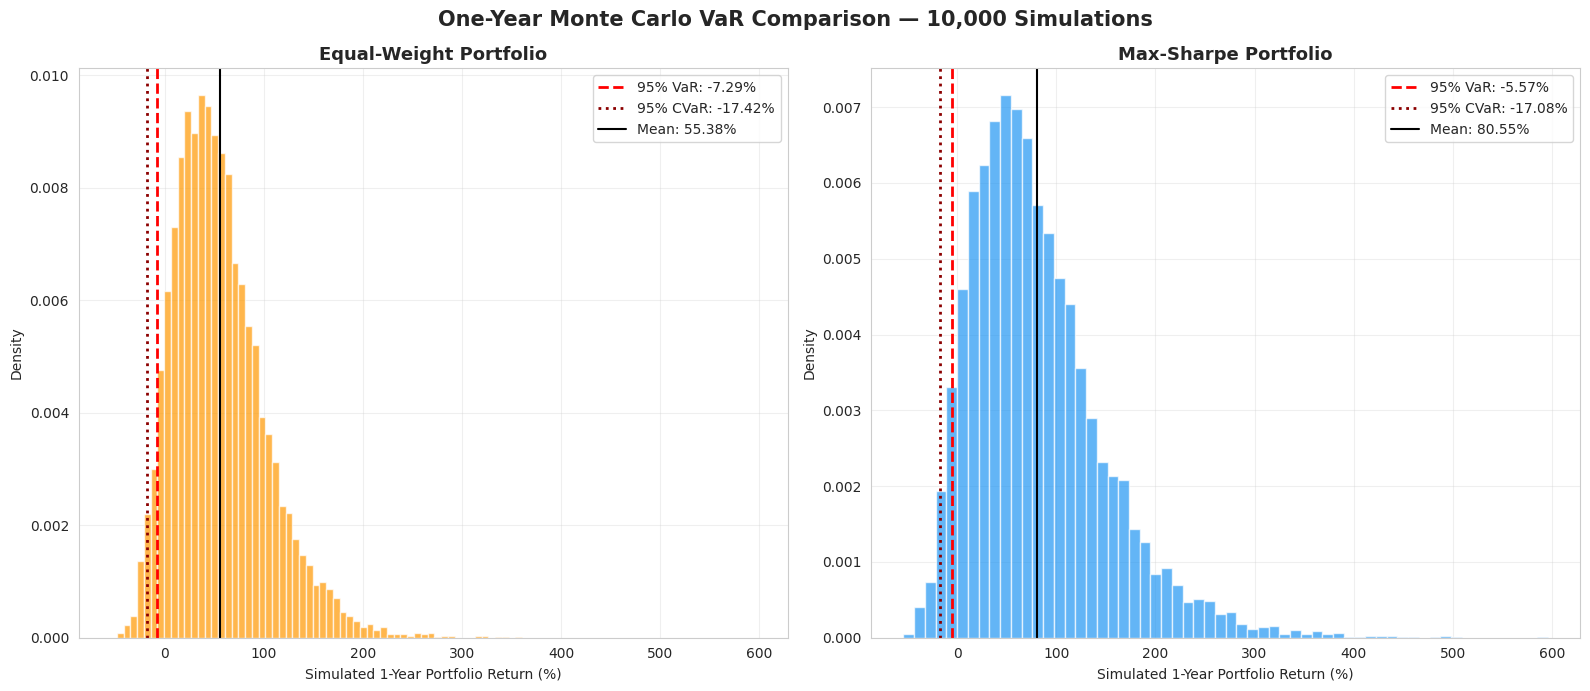

VaR / CVaR Results  (95% confidence, 1-year horizon)
                            Mean     95% VaR    95% CVaR
--------------------------------------------------------------
Equal-Weight              55.38%      -7.29%     -17.42%
Max-Sharpe                80.55%      -5.57%     -17.08%

Interpretation: 95% VaR is the 5th percentile of simulated one-year returns.
CVaR (expected shortfall) is the average return across that worst 5% tail.

Realized equal-weight return over the first simulated year: 55.94%
That outcome sits at percentile 56.7 of the simulated distribution.


In [21]:
# -----------------------------------
# Portfolio Value at Risk
# -----------------------------------

def get_var(sims, weights, prices, conf=0.95):
    growth_factors = sims[-1] / prices          # per-asset growth over the horizon
    final_growth   = growth_factors @ weights   # capital-weighted portfolio growth
    rets = (final_growth - 1) * 100
    var  = np.percentile(rets, 100 * (1 - conf))
    cvar = rets[rets <= var].mean()             # expected shortfall
    return var, cvar, rets


var_equal, cvar_equal, rets_equal = get_var(portfolio_sims, equal_weights, start_prices)
var_optimal, cvar_optimal, rets_optimal = get_var(portfolio_sims, optimal_weights.values, start_prices)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7), sharex=True)

for ax, rets, var, cvar, title, color in [
    (ax1, rets_equal, var_equal, cvar_equal, 'Equal-Weight Portfolio', '#FF9800'),
    (ax2, rets_optimal, var_optimal, cvar_optimal, 'Max-Sharpe Portfolio', '#2196F3'),
]:
    ax.hist(rets, bins=60, alpha=0.7, color=color, edgecolor='white', density=True)
    ax.axvline(var, color='red', linestyle='--', linewidth=2, label=f'95% VaR: {var:.2f}%')
    ax.axvline(cvar, color='darkred', linestyle=':', linewidth=2, label=f'95% CVaR: {cvar:.2f}%')
    ax.axvline(np.mean(rets), color='black', linewidth=1.5, label=f'Mean: {np.mean(rets):.2f}%')
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_xlabel('Simulated 1-Year Portfolio Return (%)')
    ax.set_ylabel('Density')
    ax.legend(fontsize=10)
    ax.grid(True, alpha=0.3)

plt.suptitle(f'One-Year Monte Carlo VaR Comparison — {N_SIMULATIONS:,} Simulations',
             fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

print('VaR / CVaR Results  (95% confidence, 1-year horizon)')
print('=' * 62)
print(f"{'':<22}{'Mean':>10}{'95% VaR':>12}{'95% CVaR':>12}")
print('-' * 62)
print(f"{'Equal-Weight':<22}{np.mean(rets_equal):>9.2f}%{var_equal:>11.2f}%{cvar_equal:>11.2f}%")
print(f"{'Max-Sharpe':<22}{np.mean(rets_optimal):>9.2f}%{var_optimal:>11.2f}%{cvar_optimal:>11.2f}%")

print('\nInterpretation: 95% VaR is the 5th percentile of simulated one-year returns.')
print('CVaR (expected shortfall) is the average return across that worst 5% tail.')

# Sanity check against what actually happened in the first evaluation year
realized_eq = (data_evaluation.iloc[min(HORIZON_DAYS, len(data_evaluation) - 1)] /
               data_evaluation.iloc[0] - 1).dot(equal_weights) * 100
pctile = (rets_equal < realized_eq).mean() * 100
print(f'\nRealized equal-weight return over the first simulated year: {realized_eq:.2f}%')
print(f'That outcome sits at percentile {pctile:.1f} of the simulated distribution.')

### VaR Insights

The saved **95% confidence, one-year** portfolio simulation reports:

| Portfolio | Mean simulated return | 95% VaR | 95% CVaR |
|---|---:|---:|---:|
| Equal-Weight | 55.38% | **−7.29%** | −17.42% |
| Max-Sharpe | 80.55% | **−5.57%** | −17.08% |

- The portfolio-level risk estimates use **95% confidence**, whereas the individual NVDA VaR in Section 12 uses **99% confidence**. These confidence levels should not be conflated.
- VaR is the 5th percentile of simulated portfolio returns. CVaR (expected shortfall) is the average return among scenarios in that worst 5% tail.
- The Max-Sharpe portfolio's less-negative VaR should not, by itself, be interpreted as proof that it has lower overall risk. Its simulated mean return is higher, and CVaR is close to the equal-weight result.
- These are model-based estimates. The normal-log-return and constant-parameter assumptions in GBM may understate real-world tail risk.


## 15. Rebalancing Backtest — Monthly Rebalancing vs Buy & Hold

Two equal-weight strategies are compared across the **evaluation window (2021–2025)** with $100,000 of initial capital:

- **Buy & Hold** — invest once at equal weights and let allocations drift with performance.
- **Monthly Rebalancing** — reset to equal weights at every month-end, systematically trimming winners and adding to losers.

This isolates a pure portfolio-management question: does enforcing discipline on weights help or hurt when the underlying assets trend strongly?

> Transaction costs, taxes, bid-ask spread, and market impact are **not modeled**. The comparison is therefore an idealized upper bound for the rebalancing strategy, which in reality would incur trading costs that Buy & Hold does not.

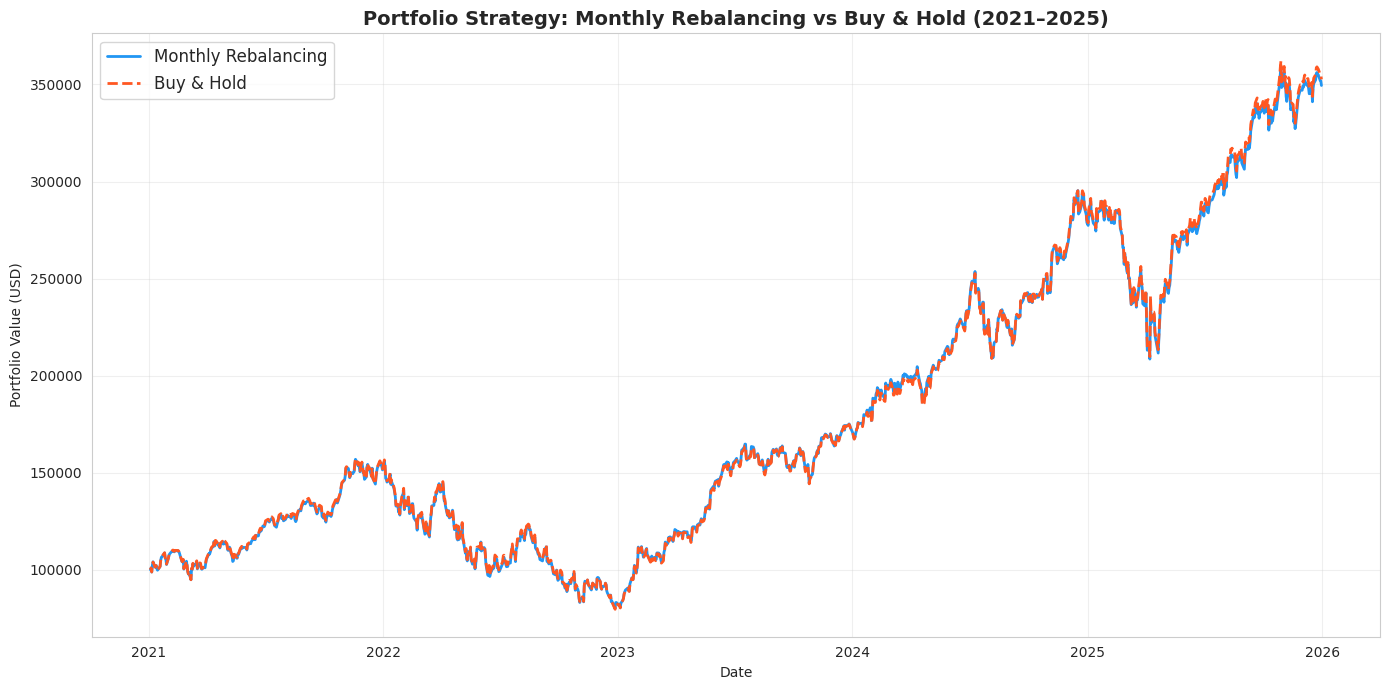

Backtest Results — 60 monthly rebalances over 1,255 trading days
                          Final Value     Return      Vol   Sharpe    Max DD
------------------------------------------------------------------
Monthly Rebalancing          $349,472     249.5%    30.2%    0.818    -48.9%
Buy & Hold                   $352,627     252.6%    30.3%    0.823    -49.4%

Difference: -3.2 percentage points

Buy & Hold weight drift by end of period:
  AAPL :  14.3%  ->    7.7%
  GOOG :  14.3%  ->   13.0%
  META :  14.3%  ->    8.8%
  AMZN :  14.3%  ->    5.1%
  MSFT :  14.3%  ->    8.2%
  NVDA :  14.3%  ->   50.6%
  TSLA :  14.3%  ->    6.6%


In [22]:
# -----------------------------------
# Monthly Rebalancing vs Buy & Hold — evaluation window
# -----------------------------------

INITIAL_CAPITAL = 100_000.0
target_w = equal_weights

# Last TRADING day of each month. Using resample('ME').index would return calendar
# month-ends, many of which are weekends and never appear in the price index —
# silently skipping those rebalances.
month_end_dates = set(
    data_evaluation.index.to_series()
    .groupby([data_evaluation.index.year, data_evaluation.index.month])
    .last()
)

portfolio_val = pd.Series(index=data_evaluation.index, dtype=float)
shares = pd.Series(0.0, index=TICKERS)
cash = INITIAL_CAPITAL
n_rebalances = 0

for i, date in enumerate(data_evaluation.index):
    prices_today = data_evaluation.loc[date]

    if i == 0 or date in month_end_dates:
        total_val = cash if i == 0 else (shares * prices_today).sum() + cash
        shares = (total_val * target_w) / prices_today
        cash = 0.0
        n_rebalances += 1 if i > 0 else 0

    portfolio_val.loc[date] = (shares * prices_today).sum() + cash

bh_rets = data_evaluation.pct_change().dropna().dot(target_w)
bh_values = pd.Series(index=data_evaluation.index, dtype=float)
bh_values.iloc[0] = INITIAL_CAPITAL
bh_values.iloc[1:] = INITIAL_CAPITAL * (1 + bh_rets).cumprod()

plt.figure(figsize=(14, 7))
plt.plot(portfolio_val.index, portfolio_val.values, label='Monthly Rebalancing',
         color='#2196F3', linewidth=2)
plt.plot(bh_values.index, bh_values.values, label='Buy & Hold',
         color='#FF5722', linewidth=2, linestyle='--')
plt.title('Portfolio Strategy: Monthly Rebalancing vs Buy & Hold (2021–2025)',
          fontsize=14, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Portfolio Value (USD)')
plt.legend(fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

rebal_ret = (portfolio_val.iloc[-1] / INITIAL_CAPITAL - 1) * 100
bh_ret    = (bh_values.iloc[-1] / INITIAL_CAPITAL - 1) * 100

rebal_daily = portfolio_val.pct_change().dropna()
bh_daily    = bh_values.pct_change().dropna()

print(f'Backtest Results — {n_rebalances} monthly rebalances over '
      f'{len(data_evaluation):,} trading days')
print('=' * 66)
print(f"{'':<22}{'Final Value':>15}{'Return':>11}{'Vol':>9}{'Sharpe':>9}{'Max DD':>10}")
print('-' * 66)

for name, daily, final in [('Monthly Rebalancing', rebal_daily, portfolio_val.iloc[-1]),
                           ('Buy & Hold', bh_daily, bh_values.iloc[-1])]:
    _, vol, sharpe, _, dd = annualized_stats(daily)
    print(f'{name:<22}{("$" + format(final, ",.0f")):>15}'
          f'{(final/INITIAL_CAPITAL-1)*100:>10.1f}%'
          f'{vol*100:>8.1f}%{sharpe:>9.3f}{dd*100:>9.1f}%')

print(f'\nDifference: {rebal_ret - bh_ret:+.1f} percentage points')

# Weight drift under Buy & Hold
final_bh_weights = (data_evaluation.iloc[-1] / data_evaluation.iloc[0]) * target_w
final_bh_weights /= final_bh_weights.sum()
print('\nBuy & Hold weight drift by end of period:')
for t in TICKERS:
    print(f'  {t:5s}: {target_w[0]*100:5.1f}%  ->  {final_bh_weights[t]*100:5.1f}%')

### Backtest Findings

- **Buy & Hold won**, finishing at **$352,627 (+252.6%)** — a few percentage points ahead of monthly rebalancing over the five-year window, and that is *before* the trading costs a real rebalancing programme would incur but Buy & Hold would not.
- The reason is momentum. Rebalancing mechanically **sells the winners**, and in a period where NVIDIA rose relentlessly, repeatedly trimming it back to a 1/7 weight was a costly discipline. Buy & Hold let the winner compound.
- The weight-drift output makes the tradeoff concrete: an untouched equal-weight portfolio ends the period **heavily concentrated in NVIDIA**, having drifted far from its 1/7 starting point. Buy & Hold's higher return came packaged with concentration risk it never deliberately chose.
- **Rebalancing was not useless** — it kept the portfolio near its intended diversification and produced a somewhat smoother path. It bought risk control and paid for it in return.
- **The result is sample-dependent, and that is the real lesson.** Rebalancing underperforms in strongly trending markets and outperforms in mean-reverting or range-bound ones. This backtest covers a single five-year technology bull run; it should not be read as a general verdict on rebalancing.

## 16. Conclusion

### What the project found

1. **Risk and correlation analysis:** Across the seven large-cap equities, the average pairwise correlation was **0.541**. The analysis also calculated Beta, Sharpe ratios and Jensen-style CAPM alpha for each stock.
2. **Individual-stock downside scenario:** The NVDA single-stock GBM simulation generated **10,000 one-year paths** and a **99% simulated VaR of −46.05%**.
3. **Correlated portfolio risk:** The seven-stock portfolio simulation generated **10,000 joint price scenarios** using GBM and Cholesky decomposition. At 95% confidence, the simulated VaR was **−7.29% for Equal-Weight** and **−5.57% for Max-Sharpe**; corresponding CVaR values were **−17.42%** and **−17.08%**.
4. **Out-of-sample portfolio performance:** The constrained long-only MPT optimizer was fitted on **2016–2020** and evaluated on the held-out **2021–2025** window. The Max-Sharpe portfolio delivered a **379.74% cumulative return** and a **0.89 Sharpe ratio**, compared with Sharpe ratios of **0.52 for the S&P 500** and **0.53 for QQQ**.
5. **Risk remained material:** Despite its higher cumulative return, the Max-Sharpe portfolio had **37.71% annualized volatility** and a **−54.00% maximum drawdown** in the evaluation period. Its Sharpe also declined from **1.542 in sample to 0.891 out of sample**.
6. **Model limitations:** The normality tests rejected normality for all seven stocks. GBM therefore serves as a transparent baseline scenario model, not a perfect representation of fat tails, changing volatility or sudden market jumps. The Magnificent 7 universe is also selected retrospectively, so survivorship/selection bias remains a limitation.
